# Task 2, step 3: GNN baselines on superpixel graphs (OASIS-1, subjects aged 60+)

Turns each prepared axial slice into a **region adjacency graph of superpixels** and trains graph neural networks on the **same subject-wise 5 folds** as the tabular and CNN/ViT baselines.

**Models, in two groups** (all from PyTorch Geometric except ViG)
- **Classic GNNs:** GCN, GraphSAGE, GATv2, ChebNet, and ViG (Vision GNN)
- **Modern GNNs:** GIN, TransformerConv, GPS (GraphGPS), GCNII, DeepGCN (GENConv), PNA

GCN, GraphSAGE, GATv2, ChebNet, GIN, TransformerConv and PNA share one architecture (3 message-passing layers, hidden size 64, BatchNorm, ReLU, mean + max readout, 2-layer classifier), and only the convolution changes, so any difference between them comes from the convolution type. The other three have their own design:
- **GPS** has, in each of 3 layers, a local GIN convolution plus global self-attention over all nodes of the graph. It uses no positional encodings, because the centroid x and y are already node features.
- **GCNII** and **DeepGCN** are built to be deep, so they use 8 layers (`DEEP_LAYERS`). GCNII adds the initial features back in every layer (initial residual). DeepGCN uses GENConv layers with residual blocks.
- **PNA** combines mean, min, max and std aggregation with degree scalers. Its degree histogram is computed on the training graphs of each fold.

**ViG is a different kind of baseline:** it works on a grid of image patches, not on the superpixel graphs, builds its graph from the features inside the network, and is trained from scratch (see section 2b). It sits in the Classic GNNs group because it was part of the first set of models. Compare it with the graph models as a separate family, not as another convolution.

**How a slice becomes a graph**
- SLIC superpixels (about 100) inside the brain mask. Each superpixel is a node.
- Two nodes are connected if their superpixels touch (8-neighbourhood).
- Node features (6): mean intensity, intensity std, centroid x, centroid y, area fraction, slice height (z).
- Superpixels are computed per image, with no information shared across subjects, so graph building cannot leak between folds. The only fitted step is the node-feature standardization, which is fitted on the **training graphs of each fold** only.

**Protocol (same as the image baselines)**
1. Outer loop: the 5 folds in `subjects_folds.csv`.
2. Inside the training folds, about 15% of the subjects are held out to pick the best epoch (lowest validation loss). The test fold is never used for any choice.
3. Training is on slices. Prediction is on **subjects**: the slice probabilities of each subject are averaged and all metrics use those 198 subject-level predictions.
4. Fixed hyperparameters, not tuned on the test folds. Out-of-fold predictions are saved in the same format as the image baselines, so paired comparisons are possible.

**Before you run:** this needs `torch_geometric` (the notebook installs it if missing, so keep **Internet on** for that first run). A GPU helps but is not essential. Set `SMOKE_TEST = True` first to check the pipeline.

In [1]:
import sys, subprocess, json, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

try:
    import torch_geometric
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch_geometric"])
    import torch_geometric

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as GeoLoader
from torch_geometric.nn import (GCNConv, SAGEConv, GATv2Conv, ChebConv, GINConv, TransformerConv,
                                GCN2Conv, GENConv, PNAConv, GPSConv,
                                global_mean_pool, global_max_pool)
from torch_geometric.utils import degree
from scipy.ndimage import binary_fill_holes
from skimage.segmentation import slic, mark_boundaries
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (roc_auc_score, balanced_accuracy_score, accuracy_score,
                             f1_score, confusion_matrix, roc_curve)
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# ----------------------------- EDIT THESE -----------------------------
DATA_DIR   = Path("/kaggle/input/notebooks/stillniloy/data-preparation-for-baselines")   # output of the data-preparation notebook
CNN_DIR = Path("/kaggle/input/notebooks/stillniloy/cnn-baselines-mri/baselines")      # output of the image-baselines notebook (optional)
TASK       = "binary"          # "binary" (CDR 0 vs >0) or "three_class" (CDR 0 / 0.5 / 1+)
SMOKE_TEST = False             # True: fold 0 only, 3 epochs, results go to a separate folder

# graph construction
N_SEGMENTS  = 100              # target number of superpixels per slice
COMPACTNESS = 0.1              # SLIC compactness for intensities in [0, 1]

# models: name -> type. The convolution models share one width/depth (HIDDEN, LAYERS).
CLASSIC_GNNS = {"GCN": "gcn", "GraphSAGE": "sage", "GATv2": "gatv2", "ChebNet": "cheb", "ViG": "vig"}
MODERN_GNNS  = {"GIN": "gin", "TransformerConv": "transformer", "GPS": "gps",
                "GCNII": "gcn2", "DeepGCN": "deepgcn", "PNA": "pna"}
GROUPS = {"Classic GNNs": CLASSIC_GNNS, "Modern GNNs": MODERN_GNNS}
RUN_GROUPS = ["Classic GNNs", "Modern GNNs"]      # remove a group here to run it in another session
GROUP_COLORS = {"Classic GNNs": "C0", "Modern GNNs": "C1"}
GNNS     = {n: k for g in RUN_GROUPS for n, k in GROUPS[g].items()}
GROUP_OF = {n: g for g, d in GROUPS.items() for n in d}
HIDDEN, LAYERS, DROPOUT = 64, 3, 0.3
HEADS   = 4                    # GATv2 attention heads (hidden // heads channels each, concatenated)
CHEB_K  = 3                    # ChebNet polynomial order
GCNII_ALPHA, GCNII_THETA = 0.1, 0.5   # GCNII: initial-residual strength and identity-mapping strength
DEEP_LAYERS = 8                # depth of the two deep models (GCNII, DeepGCN); the others use LAYERS

# optimisation
LR, WEIGHT_DECAY = 1e-3, 5e-4
BATCH, EPOCHS, PATIENCE = 64, 80, 15

# ViG: compact Vision GNN on image patches, trained from scratch (no ImageNet weights)
VIG_SIZE, VIG_DIM, VIG_BLOCKS, VIG_K = 112, 128, 6, 9      # input 112 x 112 -> 14 x 14 = 196 patch nodes
VIG_LR, VIG_WD, VIG_DROP_PATH, VIG_DROPOUT = 1e-3, 5e-2, 0.1, 0.1
VIG_EPOCHS, VIG_PATIENCE, VIG_BATCH = 40, 10, 64
VAL_FRAC    = 0.15
SEED        = 42
SAVE_EMBEDDINGS = True         # save each test fold's embeddings for the UMAP in section 6e (False skips this)
# ----------------------------------------------------------------------

if SMOKE_TEST:
    EPOCHS, VIG_EPOCHS, FOLDS = 3, 3, [0]
    OUT_DIR = Path("/kaggle/working/gnn_baselines_smoke")
else:
    FOLDS = [0, 1, 2, 3, 4]
    OUT_DIR = Path("/kaggle/working/gnn_baselines")
OUT_DIR.mkdir(parents=True, exist_ok=True)

def by_group(models):
    # [(group, [models in that group])] in group order, skipping empty groups
    return [(g, [m for m in models if GROUP_OF.get(m) == g]) for g in GROUPS if any(GROUP_OF.get(m) == g for m in models)]

def panel_axes(n, per_row=3, w=4.8, h=4.4):
    ncol = min(per_row, n); nrow = -(-n // ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(w * ncol, h * nrow), squeeze=False)
    axes = axes.ravel()
    for ax in axes[n:]: ax.axis("off")
    return fig, axes[:n]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("device:", device, "| torch", torch.__version__, "| torch_geometric", torch_geometric.__version__)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)

device: cuda | torch 2.11.0+cu128 | torch_geometric 2.8.1


## 1. Load the prepared data

In [2]:
if not (DATA_DIR / "prep_config.json").exists():          # find the prepared data if the path above is wrong
    hits = sorted(Path("/kaggle/input").rglob("prep_config.json"))
    print("found:", hits)
    assert hits, "prep_config.json not found: attach the prepared dataset or set DATA_DIR"
    DATA_DIR = hits[0].parent
cfg  = json.load(open(DATA_DIR / "prep_config.json"))
X    = np.load(DATA_DIR / "slices_60plus.npz")["X"]          # float16, (n_slices, 109, 91), values in [0, 1]
meta = pd.read_csv(DATA_DIR / "slices_meta.csv")
subs = pd.read_csv(DATA_DIR / "subjects_folds.csv")

print("normalisation:", cfg["normalisation"])
assert "fixed global scale" in cfg["normalisation"],     "old data version (per-volume p99 scaling) found: attach the updated dataset"
import hashlib
DATA_ID = hashlib.md5(X.tobytes()).hexdigest()[:8]            # fingerprint of the exact slices used
print("data fingerprint:", DATA_ID)
assert len(X) == len(meta) and (meta.row_id.values == np.arange(len(meta))).all()
assert set(meta.subject) == set(subs.subject) and subs.subject.is_unique
assert (meta.groupby("subject").fold.nunique() == 1).all(), "a subject appears in more than one fold"

LABEL_COL  = "label_bin" if TASK == "binary" else "label_3"
N_CLASSES  = 2 if TASK == "binary" else 3
y_all      = meta[LABEL_COL].values
subj_label = subs.set_index("subject")[LABEL_COL]
N_AXIAL    = 91                                              # axial slices in the 2 mm volume (91, 109, 91)

print(f"slices {tuple(X.shape)} | subjects {len(subs)} | task: {TASK} ({N_CLASSES} classes)")
print(pd.crosstab(subs.fold, subs[LABEL_COL]))

found: [PosixPath('/kaggle/input/notebooks/stillniloy/data-preparation-for-baselines/oasis1_60plus/prep_config.json')]
normalisation: fixed global scale: clip at 1.2 and divide by 1.2; per-volume p99 scaling rejected (bright tail in many scans)
data fingerprint: 7336c2d3
slices (3366, 109, 91) | subjects 198 | task: binary (2 classes)
label_bin   0   1
fold             
0          18  22
1          15  25
2          21  19
3          23  16
4          21  18


## 2. Build one superpixel graph per slice

Each slice gives a graph with about 100 nodes. Building all 3,366 graphs takes a few minutes on CPU, and the graphs are cached in `graphs_n<N_SEGMENTS>_c<COMPACTNESS>_<data fingerprint>.pt`, so a re-run loads them directly. If you change `N_SEGMENTS`, `COMPACTNESS` or the slices themselves, the cache file name changes too, so stale graphs are never reused.

In [3]:
def slice_to_graph_np(img, slice_idx):
    img = np.asarray(img, dtype=np.float32)
    H, W = img.shape
    mask = binary_fill_holes(img > 0)                         # brain mask (fills holes inside the brain)
    seg = slic(img, n_segments=N_SEGMENTS, compactness=COMPACTNESS, sigma=0,
               channel_axis=None, mask=mask, start_label=1)
    seg = np.where(mask, seg, 0)
    flat = seg.ravel()
    valid = flat > 0
    uniq, inv = np.unique(flat[valid], return_inverse=True)   # compact node ids 0..n-1
    n = len(uniq)
    lab = np.full(flat.shape, -1, dtype=np.int64)
    lab[valid] = inv
    lab = lab.reshape(H, W)

    yy, xx = np.mgrid[:H, :W]
    vals, xs, ys = img.ravel()[valid], xx.ravel()[valid], yy.ravel()[valid]
    cnt  = np.bincount(inv, minlength=n).astype(np.float64)
    mean = np.bincount(inv, weights=vals, minlength=n) / cnt
    var  = np.bincount(inv, weights=vals.astype(np.float64) ** 2, minlength=n) / cnt - mean ** 2
    std  = np.sqrt(np.clip(var, 0, None))
    cx   = np.bincount(inv, weights=xs, minlength=n) / cnt / W
    cy   = np.bincount(inv, weights=ys, minlength=n) / cnt / H
    area = cnt / (H * W)
    z    = np.full(n, slice_idx / (N_AXIAL - 1))
    feat = np.stack([mean, std, cx, cy, area, z], axis=1).astype(np.float32)

    # region adjacency graph: connect superpixels that touch (8-neighbourhood)
    pairs = []
    for a, b in [(lab[:, :-1], lab[:, 1:]), (lab[:-1, :], lab[1:, :]),
                 (lab[:-1, :-1], lab[1:, 1:]), (lab[:-1, 1:], lab[1:, :-1])]:
        m = (a >= 0) & (b >= 0) & (a != b)
        pairs.append(np.stack([a[m], b[m]], 1))
    pairs = np.concatenate(pairs, 0)
    if len(pairs):
        pairs = np.unique(np.sort(pairs, axis=1), axis=0)
        edge_index = np.concatenate([pairs, pairs[:, ::-1]], 0).T.copy()   # undirected: both directions
    else:
        edge_index = np.zeros((2, 0), dtype=np.int64)
    return feat, edge_index.astype(np.int64), seg

FEATURES = ["mean", "std", "cx", "cy", "area", "z"]
cache = OUT_DIR.parent / f"graphs_n{N_SEGMENTS}_c{COMPACTNESS}_{DATA_ID}.pt"   # tied to the exact slices

if cache.exists():
    graphs = torch.load(cache, weights_only=False)
    assert len(graphs) == len(meta), "cached graphs do not match the slices; delete the cache file"
    print("loaded", len(graphs), "graphs from", cache.name)
else:
    graphs = []
    for r in tqdm(meta.itertuples(), total=len(meta)):
        f, e, _ = slice_to_graph_np(X[r.Index], r.slice_idx)
        graphs.append(Data(x=torch.from_numpy(f), edge_index=torch.from_numpy(e),
                           y=torch.tensor([int(y_all[r.Index])]), row=torch.tensor([r.Index])))
    torch.save(graphs, cache)
    print("built and cached", len(graphs), "graphs")

n_nodes = np.array([g.num_nodes for g in graphs]); n_edges = np.array([g.edge_index.shape[1] for g in graphs])
print(f"nodes per graph: min {n_nodes.min()}, median {int(np.median(n_nodes))}, max {n_nodes.max()}")
print(f"directed edges per graph: min {n_edges.min()}, median {int(np.median(n_edges))}, max {n_edges.max()} "
      f"| mean degree {n_edges.sum() / n_nodes.sum():.1f}")
print("graphs with isolated nodes:", sum(int((torch.bincount(g.edge_index[0], minlength=g.num_nodes) == 0).any()) for g in graphs))

  0%|          | 0/3366 [00:00<?, ?it/s]

built and cached 3366 graphs
nodes per graph: min 67, median 89, max 101
directed edges per graph: min 372, median 498, max 582 | mean degree 5.6
graphs with isolated nodes: 43


A visual check on one slice: superpixel boundaries, node centroids and edges.

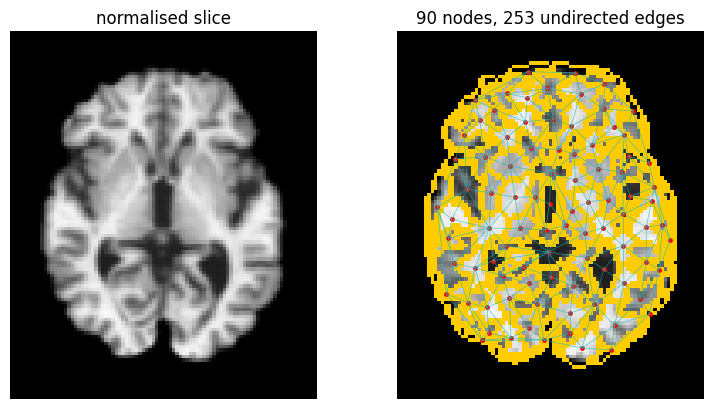

In [4]:
r = int(meta.index[meta.slice_idx == 37][0])
f, e, seg = slice_to_graph_np(X[r], int(meta.slice_idx[r]))
img = X[r].astype(np.float32)
fig, axes = plt.subplots(1, 2, figsize=(8, 4.2))
axes[0].imshow(img, cmap="gray", vmin=0, vmax=1); axes[0].set_title("normalised slice"); axes[0].axis("off")
axes[1].imshow(mark_boundaries(np.dstack([img] * 3), seg, color=(1, 0.8, 0)), interpolation="nearest")
H, W = img.shape
px, py = f[:, 2] * W, f[:, 3] * H
for a, b in e.T:
    if a < b: axes[1].plot([px[a], px[b]], [py[a], py[b]], c="c", lw=0.5, alpha=0.7)
axes[1].scatter(px, py, s=6, c="r")
axes[1].set_title(f"{len(f)} nodes, {e.shape[1] // 2} undirected edges"); axes[1].axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "graph_example.png", dpi=150); plt.show()

## 2b. ViG: Vision GNN on image patches

The slice is resized to 112 x 112 and cut into a 14 x 14 grid of patch tokens, which are the graph's nodes (196 per slice). In **every block** each node is connected to its 9 nearest nodes in feature space (so the graph changes from layer to layer and with the input), and its feature is updated by max-relative graph convolution (the largest difference between a neighbour and the node itself), followed by a feed-forward layer. This is the isotropic ViG design of Han et al. (2022) in a compact size (128 channels, 6 blocks, about 1.2M parameters), with LayerNorm in place of BatchNorm.

It is trained **from scratch**: no ImageNet weights are used, so it is closer to the simple from-scratch CNN than to the pretrained image models. With about 130 training subjects, expect it to be weaker than the pretrained baselines. Read it as a test of whether a patch-graph network can learn this task from this data alone.

In [5]:
class DropPath(nn.Module):
    def __init__(self, p):
        super().__init__(); self.p = p
    def forward(self, x):
        if not self.training or self.p == 0: return x
        keep = 1.0 - self.p
        mask = (torch.rand(x.shape[0], 1, 1, device=x.device) < keep).to(x.dtype)
        return x * mask / keep

class Grapher(nn.Module):
    # fc -> max-relative graph convolution on a feature-space kNN graph -> fc, with a residual connection
    def __init__(self, dim, k, drop_path):
        super().__init__()
        self.k = k
        self.fc1 = nn.Sequential(nn.Linear(dim, dim), nn.LayerNorm(dim))
        self.gconv = nn.Sequential(nn.Linear(2 * dim, dim), nn.LayerNorm(dim), nn.GELU())
        self.fc2 = nn.Sequential(nn.Linear(dim, dim), nn.LayerNorm(dim))
        self.dp = DropPath(drop_path)
    def forward(self, x):                                       # x: (B, N, C)
        h = self.fc1(x)
        with torch.no_grad():                                   # build the graph from the current features
            hf = F.normalize(h.float(), dim=-1)
            idx = torch.cdist(hf, hf).topk(self.k, dim=-1, largest=False).indices      # (B, N, k)
        b = torch.arange(h.shape[0], device=h.device)[:, None, None]
        nb = h[b, idx]                                          # (B, N, k, C): neighbours of every node
        rel = (nb - h.unsqueeze(2)).max(dim=2).values           # max over neighbours of (x_j - x_i)
        h = self.gconv(torch.cat([h, rel], dim=-1))
        return x + self.dp(self.fc2(h))

class FFN(nn.Module):
    def __init__(self, dim, drop_path):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, 4 * dim), nn.GELU(), nn.Linear(4 * dim, dim))
        self.dp = DropPath(drop_path)
    def forward(self, x):
        return x + self.dp(self.net(x))

class ViG(nn.Module):
    def __init__(self, n_classes, dim, blocks, k, drop_path, dropout, img_size):
        super().__init__()
        c = dim // 2
        self.stem = nn.Sequential(                              # 112 -> 56 -> 28 -> 14: one token per 8 x 8 patch
            nn.Conv2d(1, c, 3, 2, 1), nn.BatchNorm2d(c), nn.GELU(),
            nn.Conv2d(c, dim, 3, 2, 1), nn.BatchNorm2d(dim), nn.GELU(),
            nn.Conv2d(dim, dim, 3, 2, 1), nn.BatchNorm2d(dim))
        self.pos = nn.Parameter(torch.zeros(1, (img_size // 8) ** 2, dim))
        nn.init.trunc_normal_(self.pos, std=0.02)
        dps = [drop_path * i / max(blocks - 1, 1) for i in range(blocks)]
        self.blocks = nn.Sequential(*[nn.Sequential(Grapher(dim, k, dps[i]), FFN(dim, dps[i])) for i in range(blocks)])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(dim, n_classes))
    def forward(self, x):                                       # x: (B, 1, img_size, img_size)
        x = self.stem(x).flatten(2).transpose(1, 2) + self.pos
        x = self.blocks(x)
        return self.head(self.norm(x).mean(dim=1))

def make_vig():
    return ViG(N_CLASSES, VIG_DIM, VIG_BLOCKS, VIG_K, VIG_DROP_PATH, VIG_DROPOUT, VIG_SIZE)

## 3. Models, prediction and metrics

In [6]:
def make_conv(kind, d_in, d_out, deg=None):
    if kind == "gcn":   return GCNConv(d_in, d_out)
    if kind == "sage":  return SAGEConv(d_in, d_out)                       # mean aggregation
    if kind == "gatv2": return GATv2Conv(d_in, d_out // HEADS, heads=HEADS, concat=True)
    if kind == "cheb":  return ChebConv(d_in, d_out, K=CHEB_K)             # symmetric Laplacian, lambda_max = 2
    if kind == "gin":   return GINConv(nn.Sequential(nn.Linear(d_in, d_out), nn.BatchNorm1d(d_out), nn.ReLU(),
                                                    nn.Linear(d_out, d_out)), train_eps=True)
    if kind == "transformer": return TransformerConv(d_in, d_out // HEADS, heads=HEADS, concat=True)   # graph attention with query/key/value
    if kind == "pna":   return PNAConv(d_in, d_out, aggregators=["mean", "min", "max", "std"],
                                       scalers=["identity", "amplification", "attenuation"], deg=deg)
    raise ValueError(kind)

class GNN(nn.Module):
    def __init__(self, kind, d_in, hidden, n_classes, layers, dropout, deg=None):
        super().__init__()
        self.convs, self.norms, d = nn.ModuleList(), nn.ModuleList(), d_in
        for _ in range(layers):
            self.convs.append(make_conv(kind, d, hidden, deg)); self.norms.append(nn.BatchNorm1d(hidden)); d = hidden
        self.dropout = dropout
        self.head = nn.Sequential(nn.Linear(2 * hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
                                  nn.Linear(hidden, n_classes))
    def forward(self, x, edge_index, batch):
        for conv, bn in zip(self.convs, self.norms):
            x = F.dropout(F.relu(bn(conv(x, edge_index))), self.dropout, self.training)
        return self.head(torch.cat([global_mean_pool(x, batch), global_max_pool(x, batch)], 1))

def degree_hist(graph_list):
    # in-degree histogram of the given graphs, needed by PNA (each fold fits it on its training graphs only)
    ds = [degree(g.edge_index[1], g.num_nodes, dtype=torch.long) for g in graph_list]
    hist = torch.zeros(int(max(d.max() for d in ds)) + 1, dtype=torch.long)
    for d in ds: hist += torch.bincount(d, minlength=hist.numel())
    return hist

def make_head(hidden, n_classes, dropout):
    return nn.Sequential(nn.Linear(2 * hidden, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, n_classes))

def readout(x, batch):
    return torch.cat([global_mean_pool(x, batch), global_max_pool(x, batch)], 1)

class GCNII(nn.Module):
    # GCNII: every layer mixes in the initial features (initial residual) and an identity mapping, so it can go deep
    def __init__(self, d_in, hidden, n_classes, layers, dropout):
        super().__init__()
        self.lin_in = nn.Linear(d_in, hidden)
        self.convs = nn.ModuleList([GCN2Conv(hidden, GCNII_ALPHA, GCNII_THETA, layer=i + 1, shared_weights=True, normalize=True)
                                    for i in range(layers)])
        self.norms = nn.ModuleList([nn.BatchNorm1d(hidden) for _ in range(layers)])
        self.dropout = dropout
        self.head = make_head(hidden, n_classes, dropout)
    def forward(self, x, edge_index, batch):
        x = F.relu(self.lin_in(x)); x0 = x
        for conv, bn in zip(self.convs, self.norms):
            x = F.dropout(x, self.dropout, self.training)
            x = F.relu(bn(conv(x, x0, edge_index)))
        return self.head(readout(x, batch))

class DeepGEN(nn.Module):
    # DeepGCN with GENConv layers (softmax aggregation) and pre-activation residual blocks ("res+")
    def __init__(self, d_in, hidden, n_classes, layers, dropout):
        super().__init__()
        self.lin_in = nn.Linear(d_in, hidden)
        self.convs = nn.ModuleList([GENConv(hidden, hidden, aggr="softmax", t=1.0, learn_t=True, num_layers=2, norm="batch")
                                    for _ in range(layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(layers)])
        self.dropout = dropout
        self.head = make_head(hidden, n_classes, dropout)
    def forward(self, x, edge_index, batch):
        x = self.convs[0](self.lin_in(x), edge_index)
        for conv, norm in zip(self.convs[1:], self.norms[1:]):
            h = F.dropout(F.relu(norm(x)), self.dropout, self.training)
            x = x + conv(h, edge_index)
        x = F.dropout(F.relu(self.norms[0](x)), self.dropout, self.training)
        return self.head(readout(x, batch))

class GPSNet(nn.Module):
    # GraphGPS: each layer = local message passing (GIN) + global multi-head self-attention over all nodes of the graph.
    # No positional/structural encodings: the centroid x and y are already node features.
    def __init__(self, d_in, hidden, n_classes, layers, dropout):
        super().__init__()
        self.lin_in = nn.Linear(d_in, hidden)
        self.convs = nn.ModuleList([
            GPSConv(hidden, GINConv(nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden))),
                    heads=HEADS, dropout=dropout) for _ in range(layers)])
        self.head = make_head(hidden, n_classes, dropout)
    def forward(self, x, edge_index, batch):
        x = self.lin_in(x)
        for conv in self.convs:
            x = conv(x, edge_index, batch)
        return self.head(readout(x, batch))

def make_gnn(kind, deg=None):
    if kind == "gcn2":    return GCNII(len(FEATURES), HIDDEN, N_CLASSES, DEEP_LAYERS, DROPOUT)
    if kind == "deepgcn": return DeepGEN(len(FEATURES), HIDDEN, N_CLASSES, DEEP_LAYERS, DROPOUT)
    if kind == "gps":     return GPSNet(len(FEATURES), HIDDEN, N_CLASSES, LAYERS, DROPOUT)
    return GNN(kind, len(FEATURES), HIDDEN, N_CLASSES, LAYERS, DROPOUT, deg)

@torch.no_grad()
def predict(model, graph_list, mu, sd):
    model.eval()
    probs, loss_sum = [], 0.0
    for b in GeoLoader(graph_list, batch_size=BATCH * 2, shuffle=False):
        b = b.to(device)
        logits = model((b.x - mu) / sd, b.edge_index, b.batch)
        loss_sum += F.cross_entropy(logits, b.y, reduction="sum").item()
        probs.append(F.softmax(logits, 1).cpu())
    return torch.cat(probs).numpy(), loss_sum / len(graph_list)

def subject_preds(rows, probs):
    # average the slice probabilities of each subject
    d = pd.DataFrame(probs, columns=[f"p{c}" for c in range(N_CLASSES)])
    d.insert(0, "subject", meta.subject.values[np.asarray(rows)])
    g = d.groupby("subject", sort=True).mean().reset_index()
    g["y"] = g.subject.map(subj_label).values
    return g

def metrics(g):
    P, y = g[[f"p{c}" for c in range(N_CLASSES)]].values, g.y.values
    if N_CLASSES == 2:
        pred = (P[:, 1] >= 0.5).astype(int)
        auc = roc_auc_score(y, P[:, 1])
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        sens, spec, f1 = tp / (tp + fn), tn / (tn + fp), f1_score(y, pred)
    else:
        pred = P.argmax(1)
        auc = roc_auc_score(y, P, multi_class="ovr", average="macro", labels=[0, 1, 2])
        sens = spec = np.nan
        f1 = f1_score(y, pred, average="macro")
    return dict(auc=auc, bal_acc=balanced_accuracy_score(y, pred), acc=accuracy_score(y, pred),
                f1=f1, sens=sens, spec=spec)

DEG_ALL = degree_hist(graphs)         # only for this size print and the timing; each fold fits PNA's own histogram
for name, kind in GNNS.items():       # parameter counts, for the results table
    m = make_vig() if kind == "vig" else make_gnn(kind, DEG_ALL)
    print(f"{name:16s} {sum(p.numel() for p in m.parameters()) / 1e3:.1f}k parameters")

from sklearn.metrics import precision_score, recall_score

def epoch_metrics(g):
    # subject-level validation metrics for the learning curves (same decision rule as metrics())
    P, y = g[[f"p{c}" for c in range(N_CLASSES)]].values, g.y.values
    pred = (P[:, 1] >= 0.5).astype(int) if N_CLASSES == 2 else P.argmax(1)
    L = list(range(N_CLASSES))
    out = dict(val_acc=accuracy_score(y, pred))
    if N_CLASSES == 2:                                         # positive class = CDR > 0
        out["val_precision"] = precision_score(y, pred, pos_label=1, zero_division=0)
        out["val_recall"]    = recall_score(y, pred, pos_label=1, zero_division=0)
        out["val_f1"]        = f1_score(y, pred, pos_label=1, zero_division=0)
    else:                                                      # macro average over the 3 classes
        out["val_precision"] = precision_score(y, pred, labels=L, average="macro", zero_division=0)
        out["val_recall"]    = recall_score(y, pred, labels=L, average="macro", zero_division=0)
    out["val_f1_macro"]    = f1_score(y, pred, labels=L, average="macro", zero_division=0)
    out["val_f1_weighted"] = f1_score(y, pred, labels=L, average="weighted", zero_division=0)
    return out

GCN              17.5k parameters
GraphSAGE        26.1k parameters
GATv2            26.7k parameters
ChebNet          34.7k parameters
ViG              1440.3k parameters
GIN              30.4k parameters
TransformerConv  43.8k parameters
GPS              134.6k parameters
GCNII            42.6k parameters
DeepGCN          143.0k parameters
PNA              149.5k parameters


## 4. Train one model on one fold

Class-weighted cross-entropy, AdamW, cosine learning-rate decay, gradient clipping. Node features are standardized with the mean and std of the **training graphs of this fold**. The weights of the epoch with the lowest validation loss are restored before testing. Per-epoch loss, accuracy, precision, recall and F1 are saved to `*_history.csv` for the learning curves in section 5b. A (model, fold) result without a history file is trained again.

**ViG** uses its own training function (`run_fold_vig`) because it takes images, not graphs. It has the same inner validation split (same subjects, same seed), the same class weighting, early stopping on validation loss and subject-level averaging, but its own optimiser settings (`VIG_*` in the settings cell).

In [7]:
def run_fold(label, kind, k):
    seed_all(SEED + k)
    test_sub = subs[subs.fold == k]
    trainval = subs[subs.fold != k].reset_index(drop=True)

    sss = StratifiedShuffleSplit(n_splits=1, test_size=VAL_FRAC, random_state=SEED + k)
    tr_i, va_i = next(sss.split(trainval, trainval.label_3))
    tr_sub, va_sub = set(trainval.subject[tr_i]), set(trainval.subject[va_i])
    tr_rows = meta.index[meta.subject.isin(tr_sub)].values
    va_rows = meta.index[meta.subject.isin(va_sub)].values
    te_rows = meta.index[meta.subject.isin(set(test_sub.subject))].values
    assert not (tr_sub & va_sub) and not ((tr_sub | va_sub) & set(test_sub.subject))

    tr_g = [graphs[i] for i in tr_rows]; va_g = [graphs[i] for i in va_rows]; te_g = [graphs[i] for i in te_rows]

    allx = torch.cat([g.x for g in tr_g])                      # fitted on training graphs only
    mu, sd = allx.mean(0).to(device), allx.std(0).clamp_min(1e-6).to(device)

    counts = np.bincount(y_all[tr_rows], minlength=N_CLASSES).astype(float)
    w = torch.tensor(counts.sum() / (N_CLASSES * counts), dtype=torch.float32, device=device)
    crit = nn.CrossEntropyLoss(weight=w)

    gen = torch.Generator().manual_seed(SEED + k)
    tr_dl = GeoLoader(tr_g, batch_size=BATCH, shuffle=True, drop_last=True, generator=gen)

    model = make_gnn(kind, degree_hist(tr_g) if kind == "pna" else None).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

    hist = []
    best_loss, best_ep, best_state, bad = float("inf"), -1, None, 0
    t0 = time.time()
    for ep in range(EPOCHS):
        model.train(); run, seen, corr = 0.0, 0, 0
        for b in tr_dl:
            b = b.to(device)
            opt.zero_grad(set_to_none=True)
            out = model((b.x - mu) / sd, b.edge_index, b.batch)
            loss = crit(out, b.y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            run += loss.item() * b.num_graphs; seen += b.num_graphs
            corr += (out.argmax(1) == b.y).sum().item()
        sched.step()
        va_probs, va_loss = predict(model, va_g, mu, sd)
        g_va = subject_preds(va_rows, va_probs)
        va_auc = metrics(g_va)["auc"]
        hist.append(dict(model=label, fold=k, data_id=DATA_ID, epoch=ep + 1, train_loss=run / seen, train_acc=corr / seen,
                         val_loss=va_loss, val_auc=va_auc, **epoch_metrics(g_va)))
        if ep % 5 == 0 or ep == EPOCHS - 1:
            print(f"  [{label} | fold {k}] epoch {ep + 1:2d}/{EPOCHS}  train loss {run / seen:.3f}"
                  f"  val loss {va_loss:.3f}  val subject AUC {va_auc:.3f}")
        if va_loss < best_loss - 1e-4:
            best_loss, best_ep, bad = va_loss, ep + 1, 0
            best_state = {n: v.detach().cpu().clone() for n, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"  early stop at epoch {ep + 1}"); break

    model.load_state_dict(best_state)
    pd.DataFrame(hist).to_csv(OUT_DIR / f"{TASK}_{label.replace('/', '-').replace(' ', '_')}_fold{k}_history.csv", index=False)
    te_probs, _ = predict(model, te_g, mu, sd)
    g_te = subject_preds(te_rows, te_probs)
    if SAVE_EMBEDDINGS:
        subj_e, emb_e = subject_embeddings_graph(model, te_g, te_rows, mu, sd)
        assert (subj_e == g_te.subject.values.astype(str)).all()
        np.savez_compressed(OUT_DIR / f"{TASK}_{label.replace('/', '-').replace(' ', '_')}_fold{k}_emb.npz",
                            subject=subj_e, emb=emb_e, model=np.array(label), fold=np.array(k))
    res = dict(model=label, fold=k, best_epoch=best_ep, n_params_k=round(n_params / 1e3, 1),
               n_train_subjects=len(tr_sub), n_val_subjects=len(va_sub), n_test_subjects=len(g_te),
               minutes=round((time.time() - t0) / 60, 1), **metrics(g_te))
    return res, g_te

# ------------------------------------------------------------------ ViG (image input)
X_t = torch.from_numpy(X.astype(np.float32))                    # (n_slices, 109, 91), about 130 MB
vig_aug = T.RandomAffine(degrees=8, translate=(0.05, 0.05), scale=(0.95, 1.05))

class SliceDS(Dataset):
    def __init__(self, rows, train):
        self.rows, self.train = np.asarray(rows), train
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = int(self.rows[i])
        x = X_t[r].unsqueeze(0)                                 # (1, 109, 91)
        if self.train:
            x = vig_aug(x)
            x = (x * random.uniform(0.9, 1.1) + random.uniform(-0.03, 0.03)).clamp(0, 1)
        return x, int(y_all[r])

def vig_prep(x):
    x = F.interpolate(x, size=(VIG_SIZE, VIG_SIZE), mode="bilinear", align_corners=False)
    return (x - 0.449) / 0.226

@torch.no_grad()
def predict_vig(model, rows):
    model.eval()
    dl = DataLoader(SliceDS(rows, False), batch_size=VIG_BATCH * 2, shuffle=False, num_workers=2)
    probs, loss_sum = [], 0.0
    for x, y in dl:
        x, y = vig_prep(x.to(device, non_blocking=True)), y.to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(x)
        logits = logits.float()
        loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
        probs.append(F.softmax(logits, 1).cpu())
    return torch.cat(probs).numpy(), loss_sum / len(rows)

def run_fold_vig(label, k):
    seed_all(SEED + k)
    test_sub = subs[subs.fold == k]
    trainval = subs[subs.fold != k].reset_index(drop=True)

    sss = StratifiedShuffleSplit(n_splits=1, test_size=VAL_FRAC, random_state=SEED + k)    # same split as the GNNs
    tr_i, va_i = next(sss.split(trainval, trainval.label_3))
    tr_sub, va_sub = set(trainval.subject[tr_i]), set(trainval.subject[va_i])
    tr_rows = meta.index[meta.subject.isin(tr_sub)].values
    va_rows = meta.index[meta.subject.isin(va_sub)].values
    te_rows = meta.index[meta.subject.isin(set(test_sub.subject))].values
    assert not (tr_sub & va_sub) and not ((tr_sub | va_sub) & set(test_sub.subject))

    gen = torch.Generator().manual_seed(SEED + k)
    tr_dl = DataLoader(SliceDS(tr_rows, True), batch_size=VIG_BATCH, shuffle=True, drop_last=True,
                       num_workers=2, pin_memory=True, generator=gen)

    counts = np.bincount(y_all[tr_rows], minlength=N_CLASSES).astype(float)
    w = torch.tensor(counts.sum() / (N_CLASSES * counts), dtype=torch.float32, device=device)
    crit = nn.CrossEntropyLoss(weight=w)

    model = make_vig().to(device)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.AdamW(model.parameters(), lr=VIG_LR, weight_decay=VIG_WD)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=VIG_LR, total_steps=VIG_EPOCHS * len(tr_dl), pct_start=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    hist = []
    best_loss, best_ep, best_state, bad = float("inf"), -1, None, 0
    t0 = time.time()
    for ep in range(VIG_EPOCHS):
        model.train(); run, seen, corr = 0.0, 0, 0
        for x, y in tr_dl:
            x, y = vig_prep(x.to(device, non_blocking=True)), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
            loss = crit(out.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item() * len(y); seen += len(y)
            corr += (out.argmax(1) == y).sum().item()
        va_probs, va_loss = predict_vig(model, va_rows)
        g_va = subject_preds(va_rows, va_probs)
        va_auc = metrics(g_va)["auc"]
        hist.append(dict(model=label, fold=k, data_id=DATA_ID, epoch=ep + 1, train_loss=run / seen, train_acc=corr / seen,
                         val_loss=va_loss, val_auc=va_auc, **epoch_metrics(g_va)))
        if ep % 5 == 0 or ep == VIG_EPOCHS - 1:
            print(f"  [{label} | fold {k}] epoch {ep + 1:2d}/{VIG_EPOCHS}  train loss {run / seen:.3f}"
                  f"  val loss {va_loss:.3f}  val subject AUC {va_auc:.3f}")
        if va_loss < best_loss - 1e-4:
            best_loss, best_ep, bad = va_loss, ep + 1, 0
            best_state = {n: v.detach().cpu().clone() for n, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= VIG_PATIENCE:
                print(f"  early stop at epoch {ep + 1}"); break

    model.load_state_dict(best_state)
    pd.DataFrame(hist).to_csv(OUT_DIR / f"{TASK}_{label.replace('/', '-').replace(' ', '_')}_fold{k}_history.csv", index=False)
    te_probs, _ = predict_vig(model, te_rows)
    g_te = subject_preds(te_rows, te_probs)
    if SAVE_EMBEDDINGS:
        subj_e, emb_e = subject_embeddings_vig(model, te_rows)
        assert (subj_e == g_te.subject.values.astype(str)).all()
        np.savez_compressed(OUT_DIR / f"{TASK}_{label.replace('/', '-').replace(' ', '_')}_fold{k}_emb.npz",
                            subject=subj_e, emb=emb_e, model=np.array(label), fold=np.array(k))
    res = dict(model=label, fold=k, best_epoch=best_ep, n_params_k=round(n_params / 1e3, 1),
               n_train_subjects=len(tr_sub), n_val_subjects=len(va_sub), n_test_subjects=len(g_te),
               minutes=round((time.time() - t0) / 60, 1), **metrics(g_te))
    del model, opt, best_state
    torch.cuda.empty_cache()
    return res, g_te


@torch.no_grad()
def subject_embeddings_graph(model, graph_list, rows, mu, sd):
    # the input of the classifier head (mean + max readout of the nodes), averaged over each subject's slices
    model.eval()
    cap = []
    hk = model.head.register_forward_hook(lambda mod, inp, out: cap.append(inp[0].detach().float().flatten(1).cpu()))
    try:
        for b in GeoLoader(graph_list, batch_size=BATCH * 2, shuffle=False):
            b = b.to(device)
            model((b.x - mu) / sd, b.edge_index, b.batch)
    finally:
        hk.remove()
    return _mean_per_subject(torch.cat(cap).numpy(), rows)

@torch.no_grad()
def subject_embeddings_vig(model, rows):
    # ViG: the pooled node features that go into the classifier head
    model.eval()
    cap = []
    hk = model.head.register_forward_hook(lambda mod, inp, out: cap.append(inp[0].detach().float().flatten(1).cpu()))
    dl = DataLoader(SliceDS(rows, False), batch_size=VIG_BATCH * 2, shuffle=False, num_workers=2)
    try:
        for x, _ in dl:
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                model(vig_prep(x.to(device, non_blocking=True)))
    finally:
        hk.remove()
    return _mean_per_subject(torch.cat(cap).numpy(), rows)

def _mean_per_subject(E, rows):
    d = pd.DataFrame(E)
    d.insert(0, "subject", meta.subject.values[np.asarray(rows)])
    g = d.groupby("subject", sort=True).mean()                  # same subject order as subject_preds()
    return g.index.values.astype(str), g.values.astype(np.float32)


## 4b. Check that every model builds and runs

Builds every model, runs one tiny batch of 4 graphs (and 2 slices for ViG) through it, and for the graph models also runs a backward pass. A wrong layer argument or a version problem in `torch_geometric` shows up here in seconds instead of in the middle of a long run.

In [8]:
from torch_geometric.data import Batch

chk_b = Batch.from_data_list(graphs[:4]).to(device)
chk = []
for name, kind in GNNS.items():
    cap = []
    if kind == "vig":
        m = make_vig().to(device).eval()
        hk = m.head.register_forward_hook(lambda mod, inp, out: cap.append(inp[0].detach().flatten(1)))
        with torch.no_grad():
            out = m(vig_prep(torch.zeros(2, 1, 109, 91, device=device)))
        hk.remove()
        assert tuple(out.shape) == (2, N_CLASSES), (name, out.shape)
    else:
        m = make_gnn(kind, DEG_ALL).to(device).train()
        hk = m.head.register_forward_hook(lambda mod, inp, out: cap.append(inp[0].detach().flatten(1)))
        out = m((chk_b.x - chk_b.x.mean(0)) / chk_b.x.std(0).clamp_min(1e-6), chk_b.edge_index, chk_b.batch)
        hk.remove()
        out.sum().backward()
        assert tuple(out.shape) == (4, N_CLASSES), (name, out.shape)
    assert len(cap) == 1, f"{name}: could not capture the embedding"
    chk.append(dict(model=name, group=GROUP_OF[name], type=kind,
                    params_k=round(sum(p.numel() for p in m.parameters()) / 1e3, 1), emb_dim=cap[0].shape[1]))
    del m
print(pd.DataFrame(chk).to_string(index=False))

          model        group        type  params_k  emb_dim
            GCN Classic GNNs         gcn      17.5      128
      GraphSAGE Classic GNNs        sage      26.1      128
          GATv2 Classic GNNs       gatv2      26.7      128
        ChebNet Classic GNNs        cheb      34.7      128
            ViG Classic GNNs         vig    1440.3      128
            GIN  Modern GNNs         gin      30.4      128
TransformerConv  Modern GNNs transformer      43.8      128
            GPS  Modern GNNs         gps     134.6      128
          GCNII  Modern GNNs        gcn2      42.6      128
        DeepGCN  Modern GNNs     deepgcn     143.0      128
            PNA  Modern GNNs         pna     149.5      128


## 5. Run all models and folds

Each (model, fold) result is saved as soon as it finishes, so a stopped session can resume by re-running this cell.

In [9]:
def safe(s): return s.replace("/", "-").replace(" ", "_")

for label, kind in GNNS.items():
    for k in FOLDS:
        f_json  = OUT_DIR / f"{TASK}_{safe(label)}_fold{k}.json"
        f_preds = OUT_DIR / f"{TASK}_{safe(label)}_fold{k}_preds.csv"
        f_hist  = OUT_DIR / f"{TASK}_{safe(label)}_fold{k}_history.csv"
        f_emb   = OUT_DIR / f"{TASK}_{safe(label)}_fold{k}_emb.npz"
        if f_json.exists() and f_preds.exists() and f_hist.exists() and (f_emb.exists() or not SAVE_EMBEDDINGS):
            if json.load(open(f_json)).get("data_id") == DATA_ID:
                print(f"skip {label} fold {k} (already done)"); continue
            print(f"{label} fold {k}: saved result is from different data, re-running")
        print(f"\n=== {label} | fold {k} ===")
        res, g_te = run_fold_vig(label, k) if kind == "vig" else run_fold(label, kind, k)
        res["data_id"] = DATA_ID; res["group"] = GROUP_OF[label]
        g_te.insert(1, "fold", k); g_te.insert(2, "model", label)
        g_te.to_csv(f_preds, index=False)
        f_json.write_text(json.dumps(res, indent=2))
        print(f"  TEST  AUC {res['auc']:.3f} | bal.acc {res['bal_acc']:.3f} | F1 {res['f1']:.3f} "
              f"| best epoch {res['best_epoch']} | {res['minutes']} min")

json.dump(dict(task=TASK, gnns=GNNS, groups={g: list(d) for g, d in GROUPS.items()}, run_groups=RUN_GROUPS,
               deep_layers=DEEP_LAYERS, gcnii=dict(alpha=GCNII_ALPHA, theta=GCNII_THETA),
               vig=dict(size=VIG_SIZE, dim=VIG_DIM, blocks=VIG_BLOCKS, k=VIG_K, lr=VIG_LR, weight_decay=VIG_WD,
                        drop_path=VIG_DROP_PATH, dropout=VIG_DROPOUT, epochs=VIG_EPOCHS, patience=VIG_PATIENCE, batch=VIG_BATCH),
               n_segments=N_SEGMENTS, compactness=COMPACTNESS, features=FEATURES,
               hidden=HIDDEN, layers=LAYERS, dropout=DROPOUT, heads=HEADS, cheb_k=CHEB_K, lr=LR,
               weight_decay=WEIGHT_DECAY, batch=BATCH, epochs=EPOCHS, patience=PATIENCE, val_frac=VAL_FRAC,
               seed=SEED, folds=FOLDS, data_id=DATA_ID, prep_config=cfg),
          open(OUT_DIR / f"{TASK}_run_config.json", "w"), indent=2)


=== GCN | fold 0 ===
  [GCN | fold 0] epoch  1/80  train loss 0.716  val loss 0.679  val subject AUC 0.681
  [GCN | fold 0] epoch  6/80  train loss 0.655  val loss 0.660  val subject AUC 0.701
  [GCN | fold 0] epoch 11/80  train loss 0.649  val loss 0.656  val subject AUC 0.694
  [GCN | fold 0] epoch 16/80  train loss 0.639  val loss 0.654  val subject AUC 0.715
  [GCN | fold 0] epoch 21/80  train loss 0.639  val loss 0.654  val subject AUC 0.701
  [GCN | fold 0] epoch 26/80  train loss 0.636  val loss 0.655  val subject AUC 0.688
  [GCN | fold 0] epoch 31/80  train loss 0.625  val loss 0.662  val subject AUC 0.715
  early stop at epoch 31
  TEST  AUC 0.730 | bal.acc 0.593 | F1 0.514 | best epoch 16 | 0.2 min

=== GCN | fold 1 ===
  [GCN | fold 1] epoch  1/80  train loss 0.705  val loss 0.666  val subject AUC 0.790
  [GCN | fold 1] epoch  6/80  train loss 0.659  val loss 0.642  val subject AUC 0.790
  [GCN | fold 1] epoch 11/80  train loss 0.649  val loss 0.651  val subject AUC 0.769


## 5b. Learning curves

One value per epoch, saved in `*_history.csv` (one file per model and fold) while training. **Solid lines** are the validation set, measured at **subject level** like all other metrics. **Dashed lines** are training loss and accuracy, measured on slices during the epoch (with augmentation and dropout on), so they are not directly comparable with the validation lines.

- Loss is the cross-entropy. Accuracy, precision, recall and F1 use the same 0.5 / argmax rule as the results. In the binary task, precision, recall and F1 are for CDR > 0. In the three-class task, precision and recall are macro averages.
- The validation set is only about 15% of the training subjects, so the curves are noisy.
- Training stops early on validation loss, so different folds stop at different epochs. The bold line is the mean over the folds that reached that epoch (at least 2 folds), and the thin lines are single folds. The weights used for testing are from the epoch with the lowest validation loss, not the last epoch.

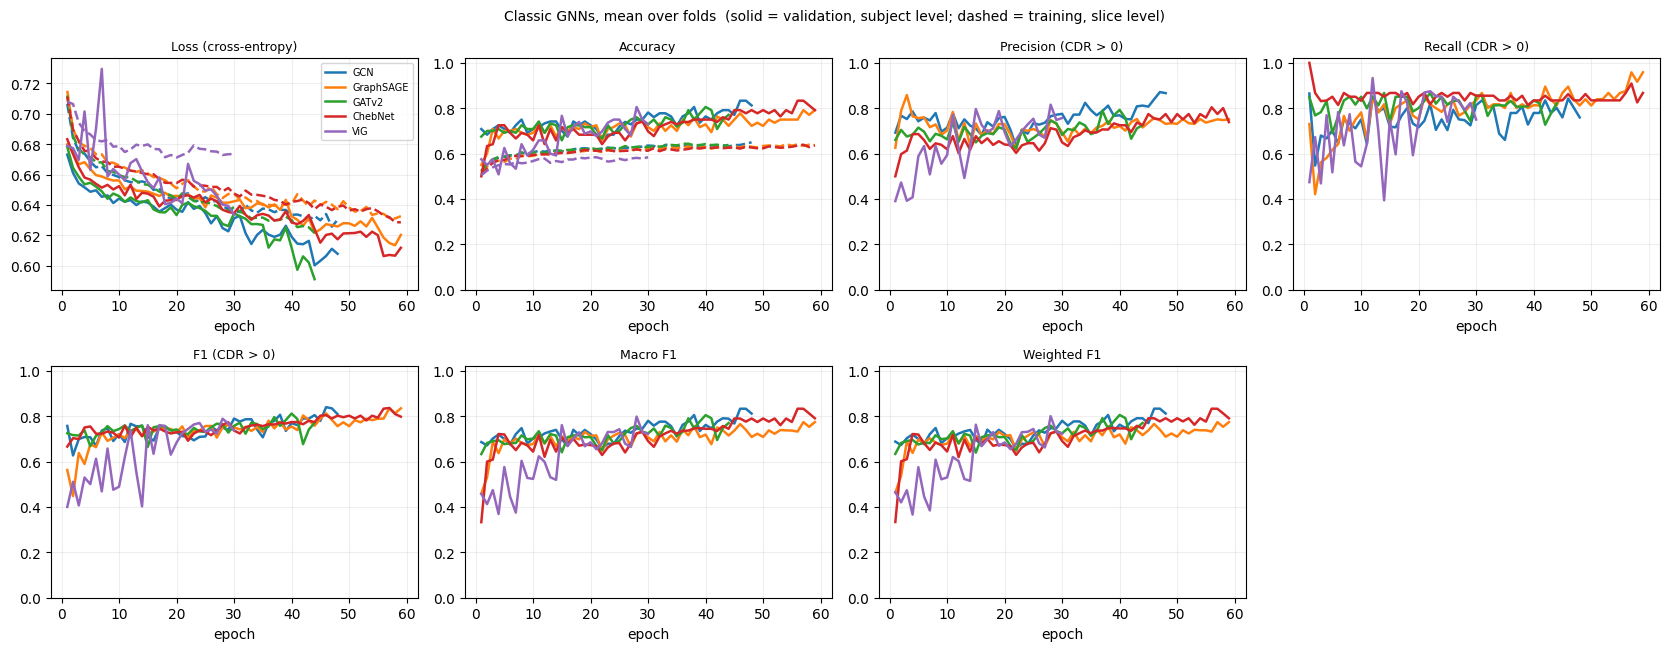

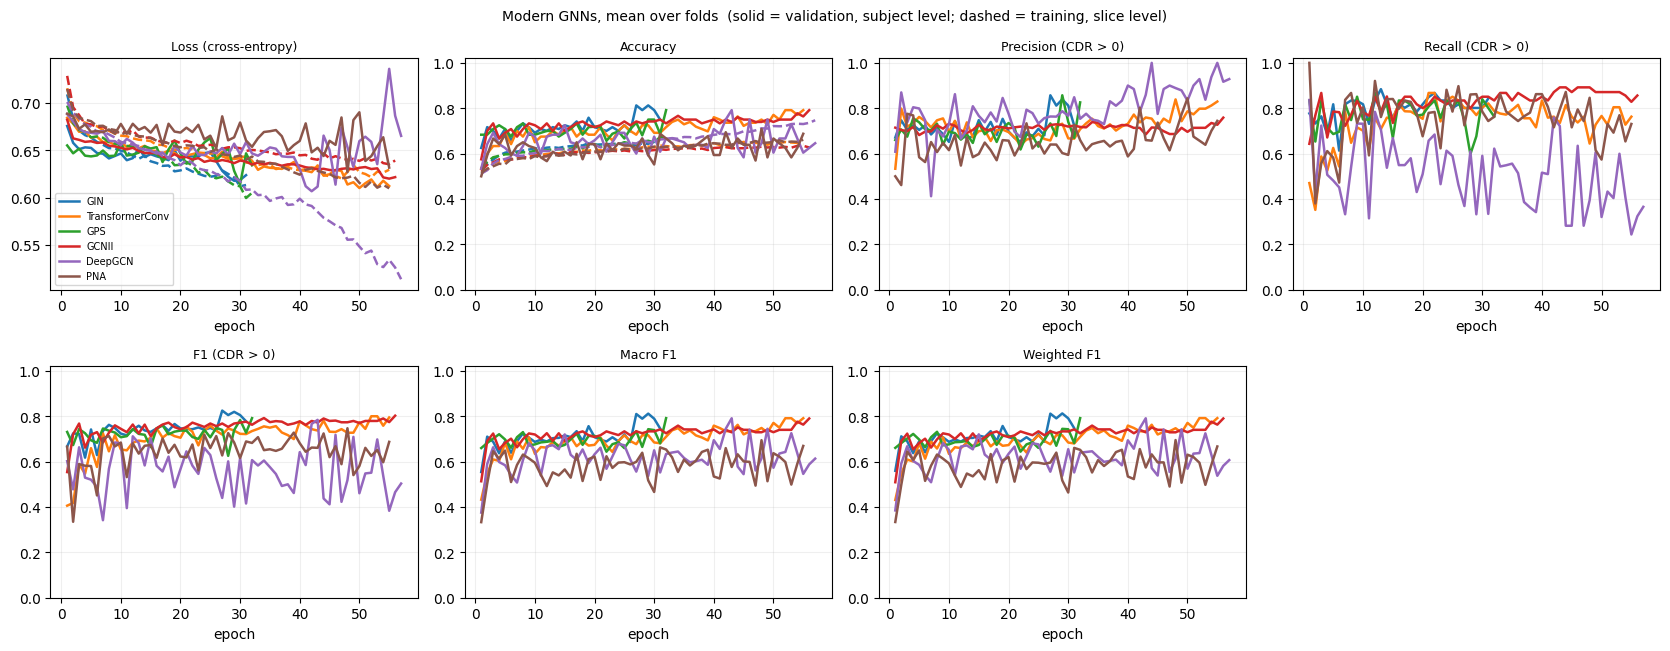

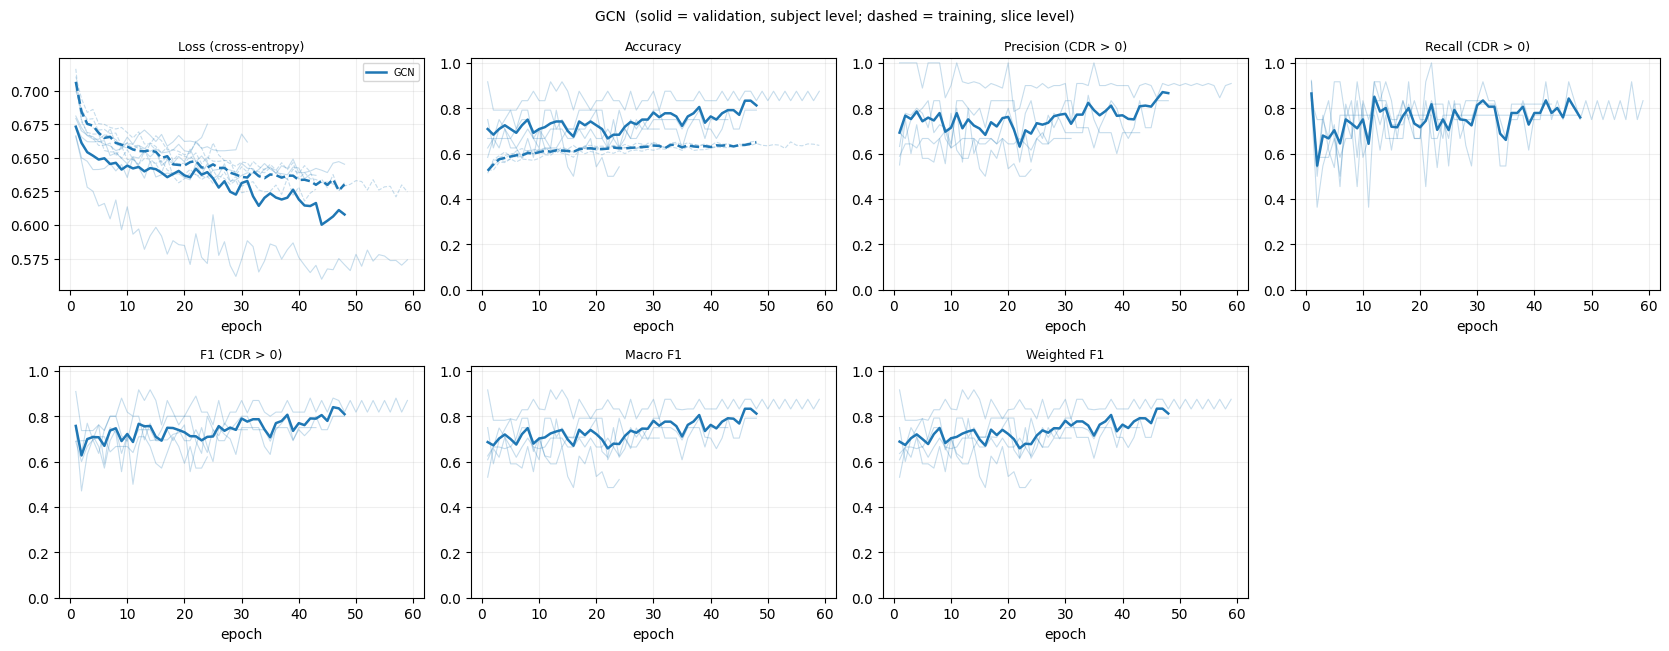

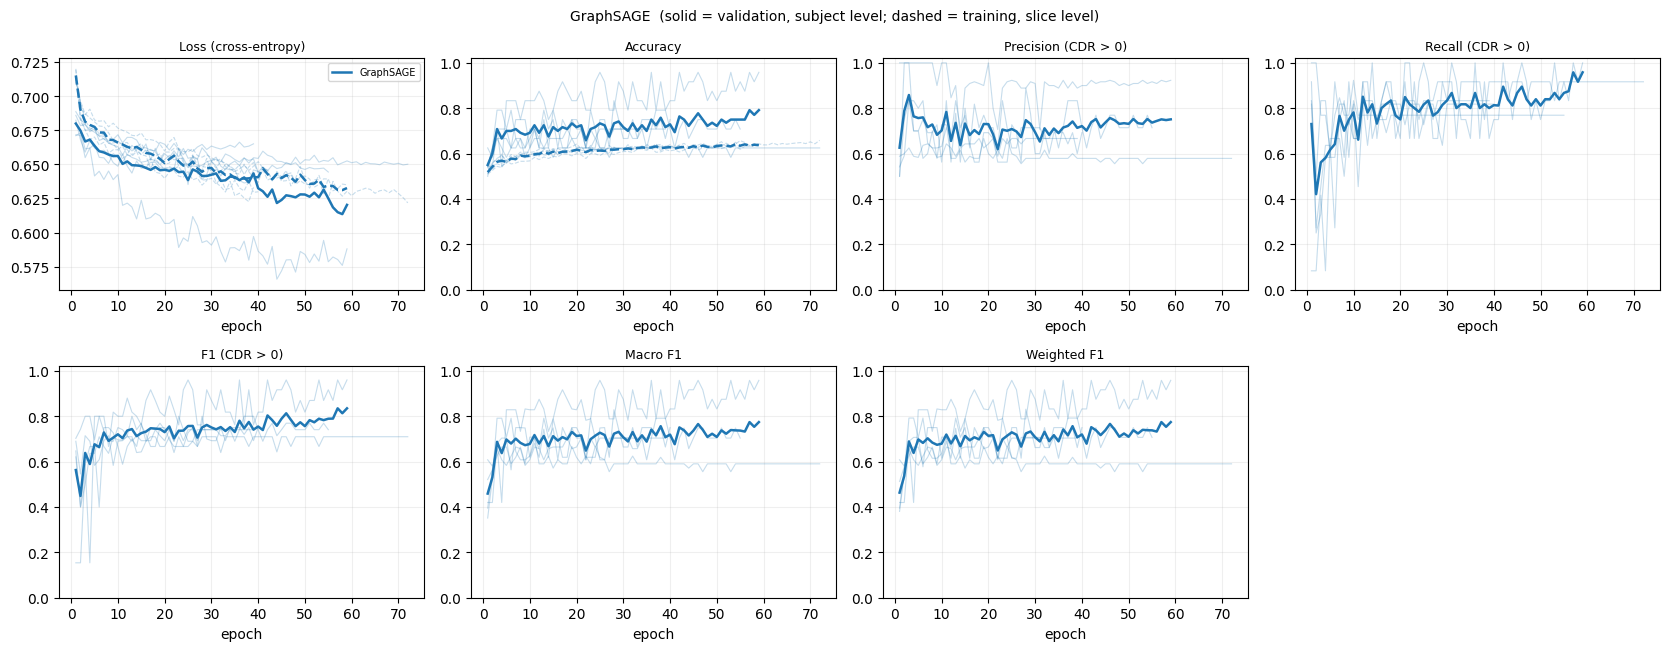

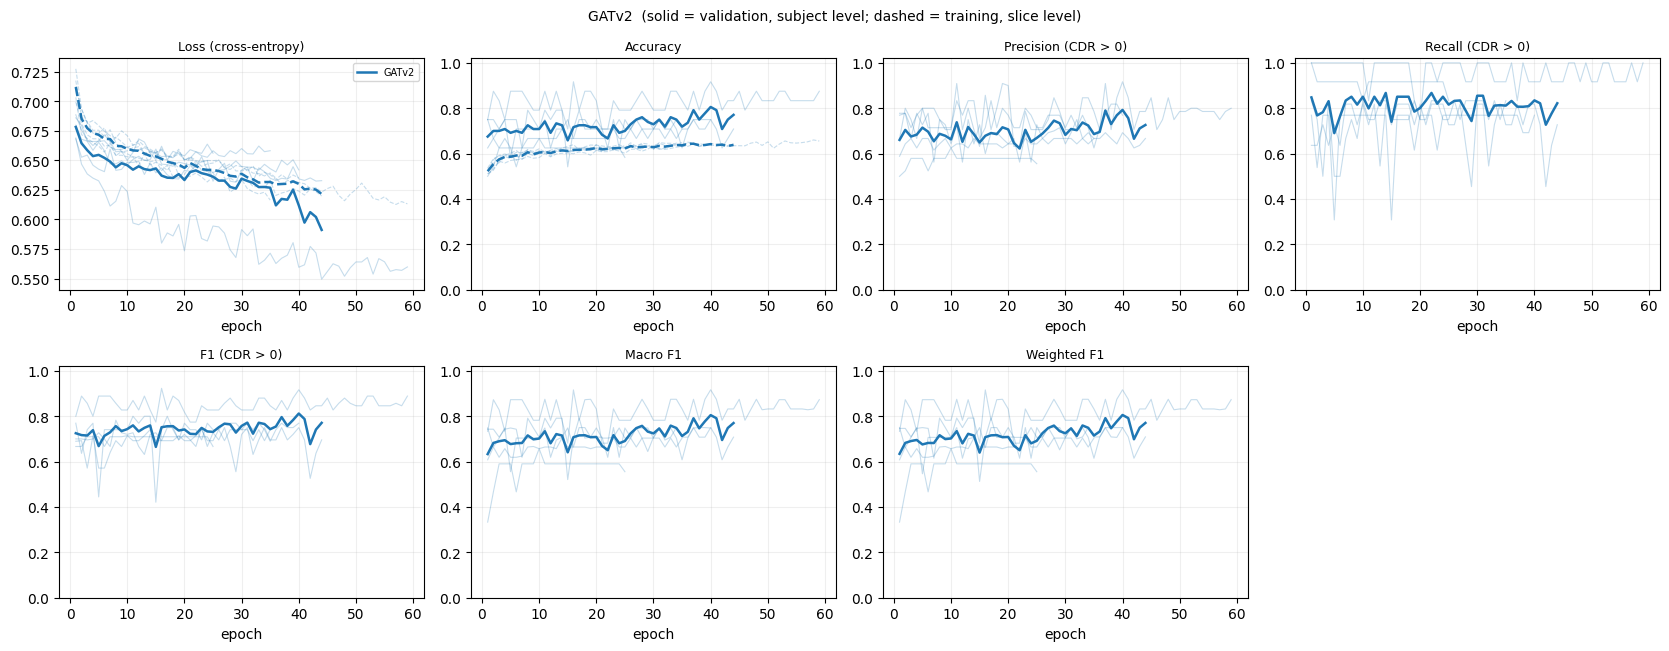

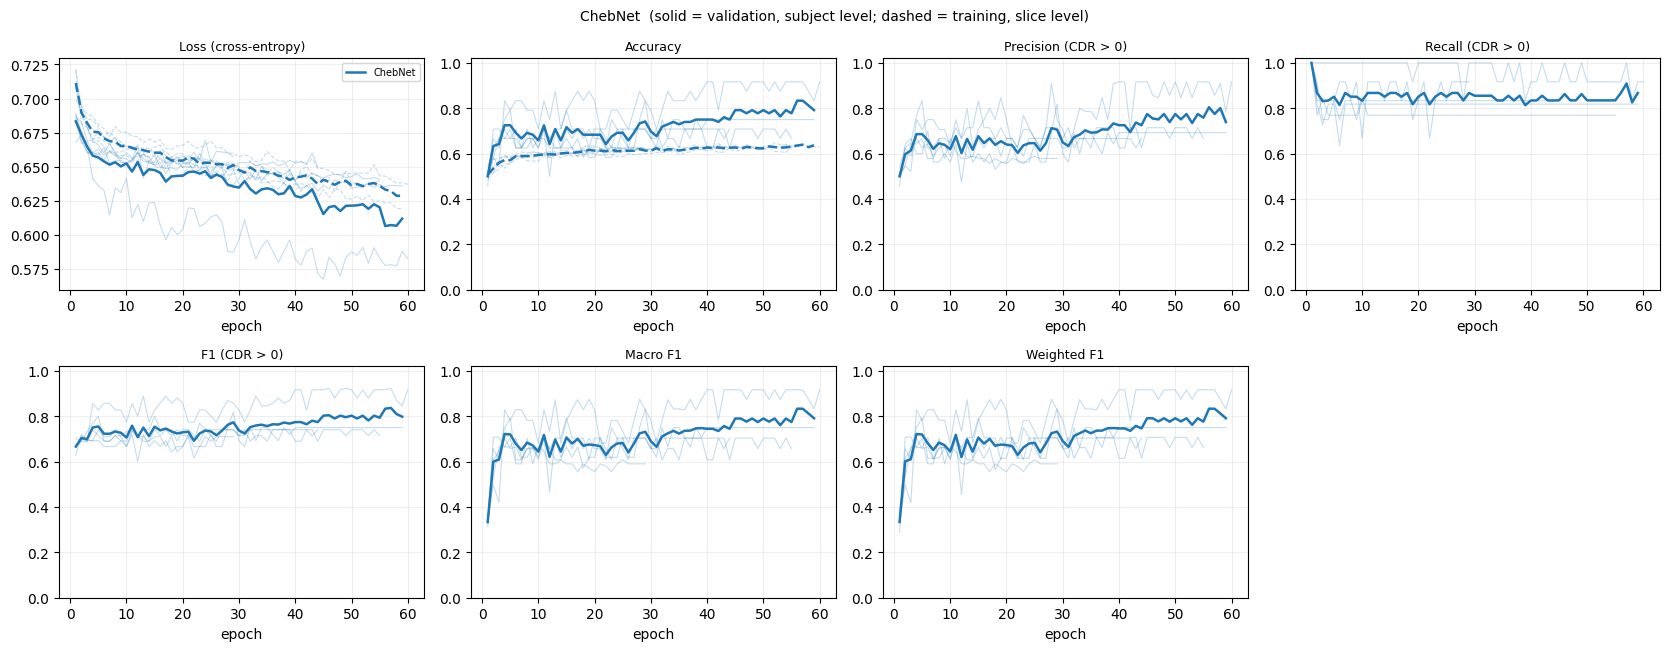

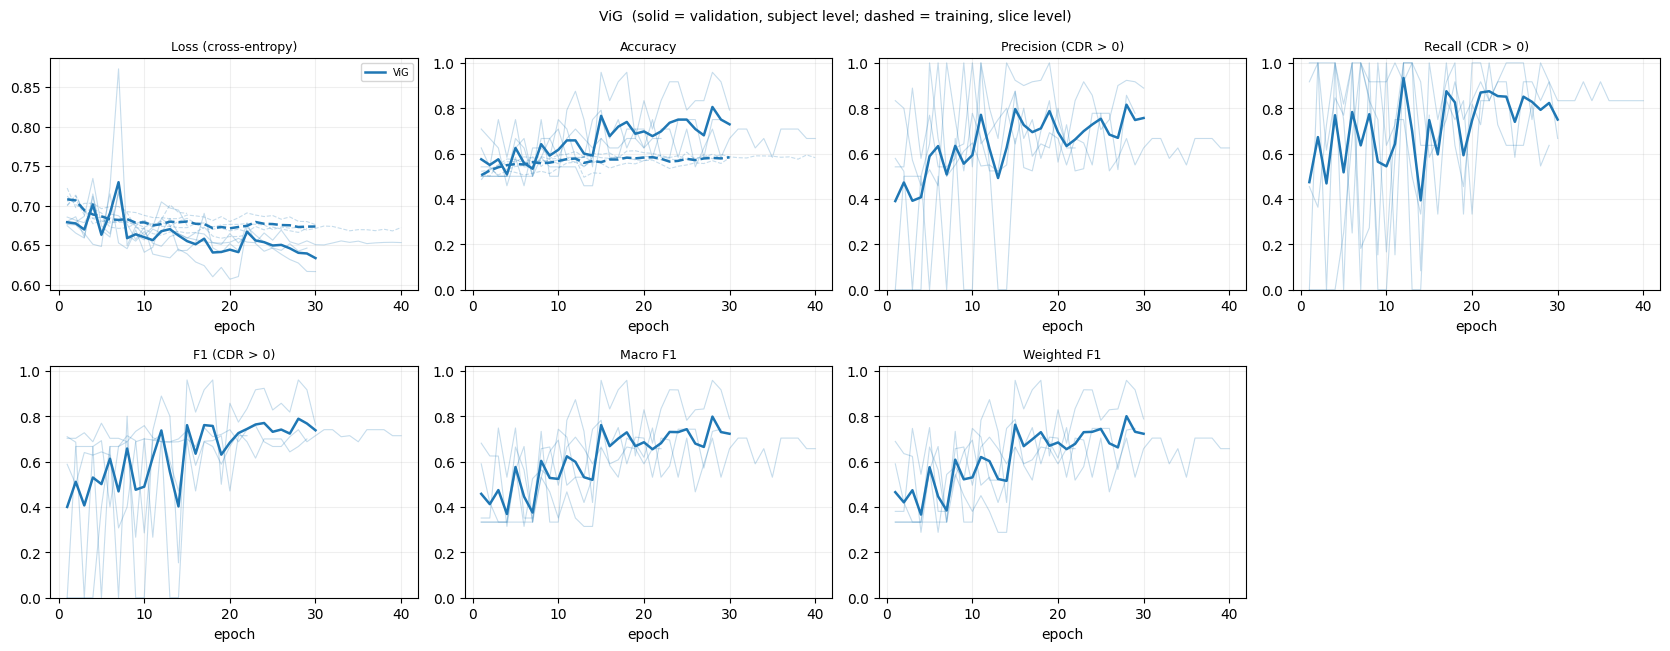

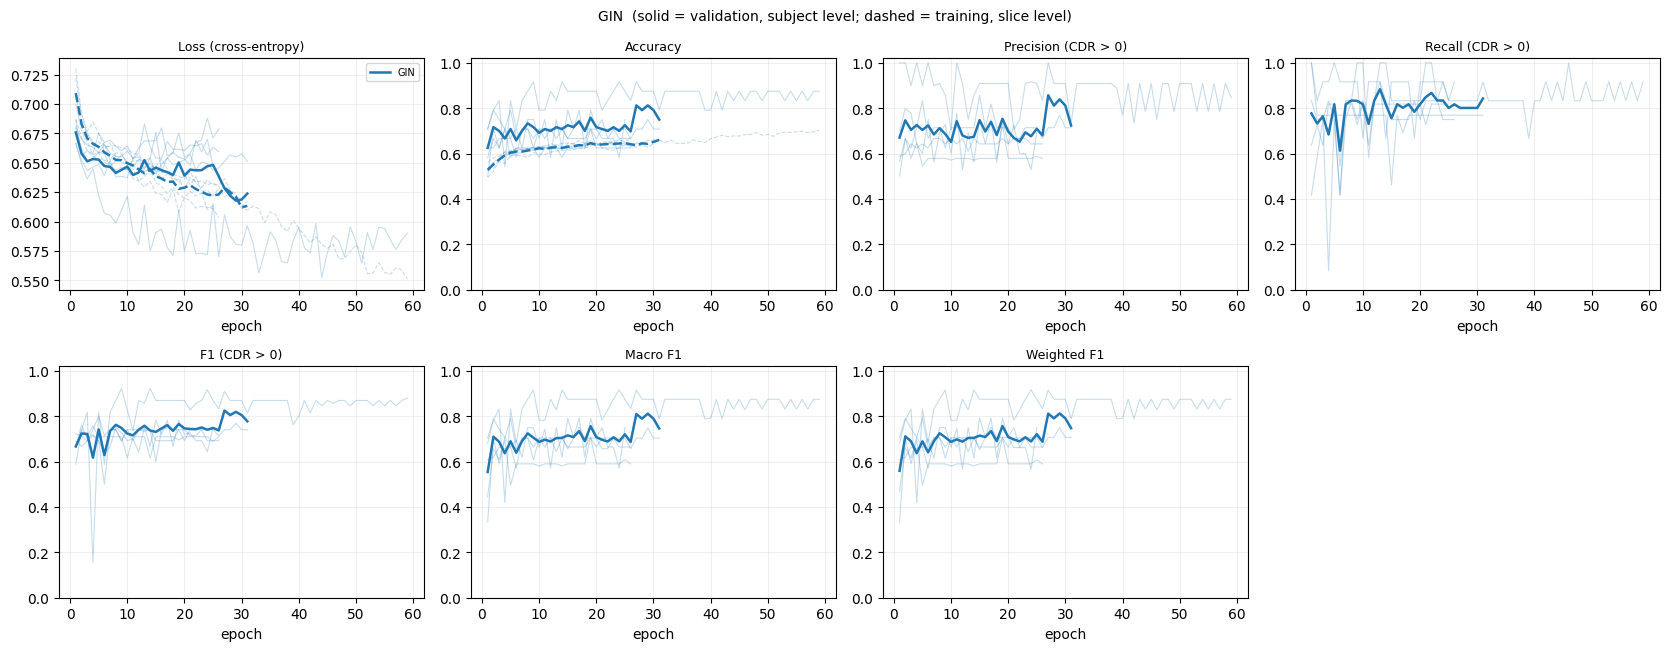

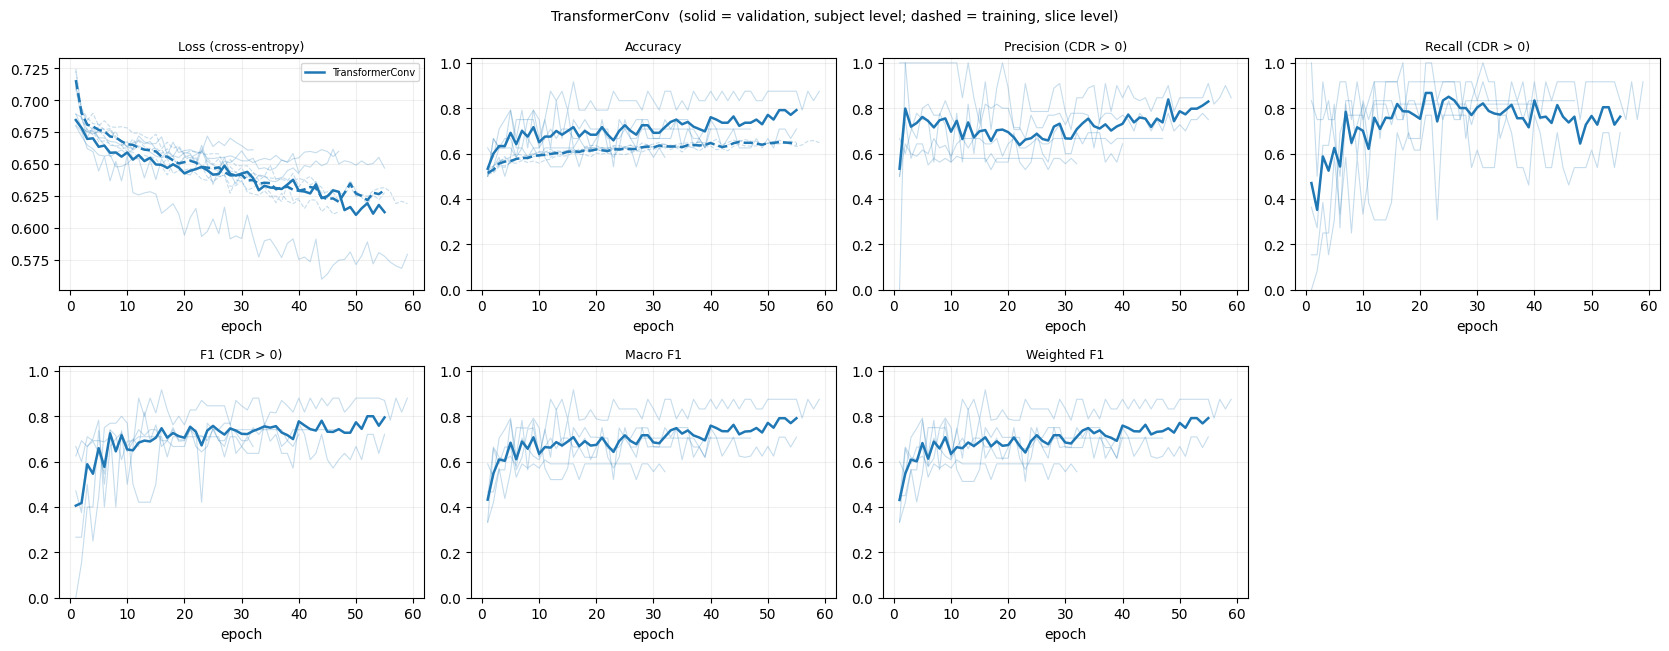

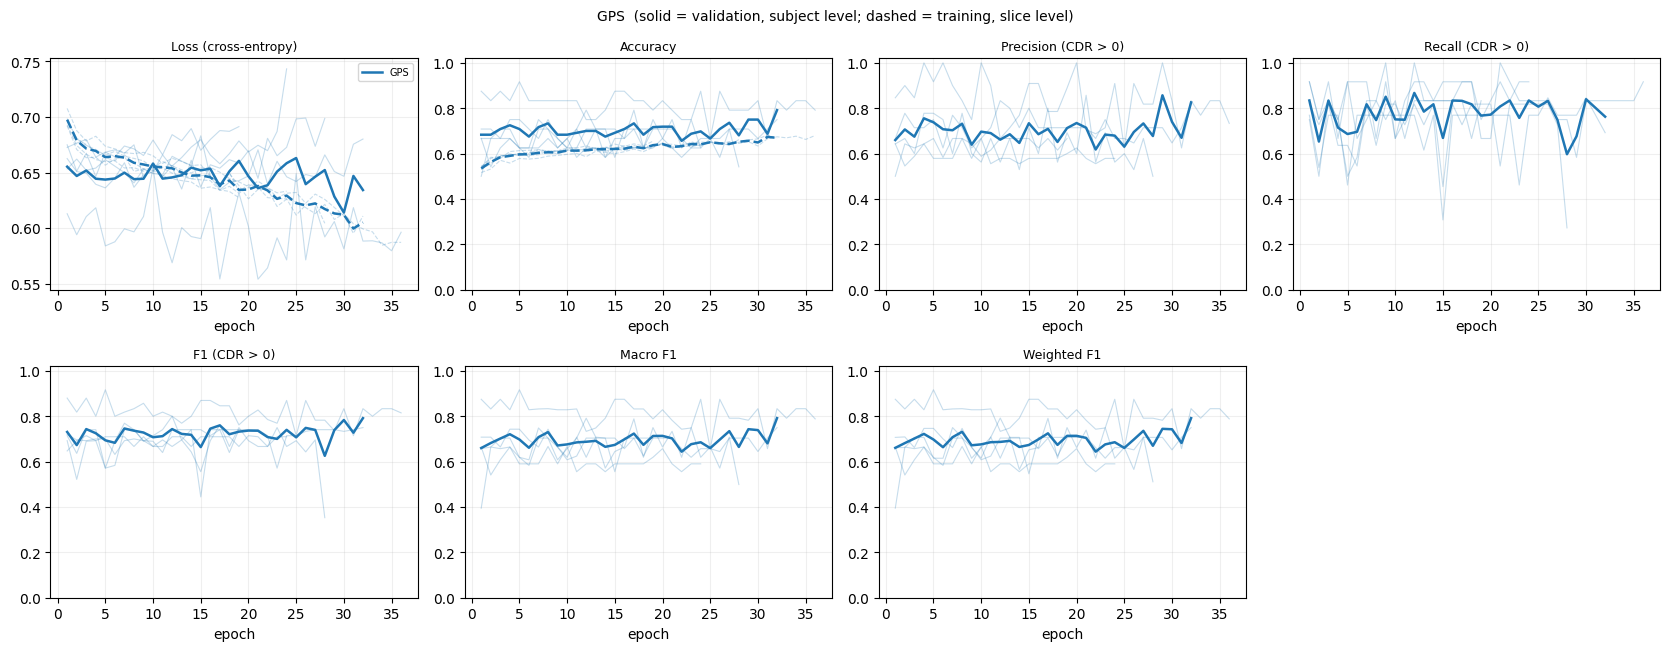

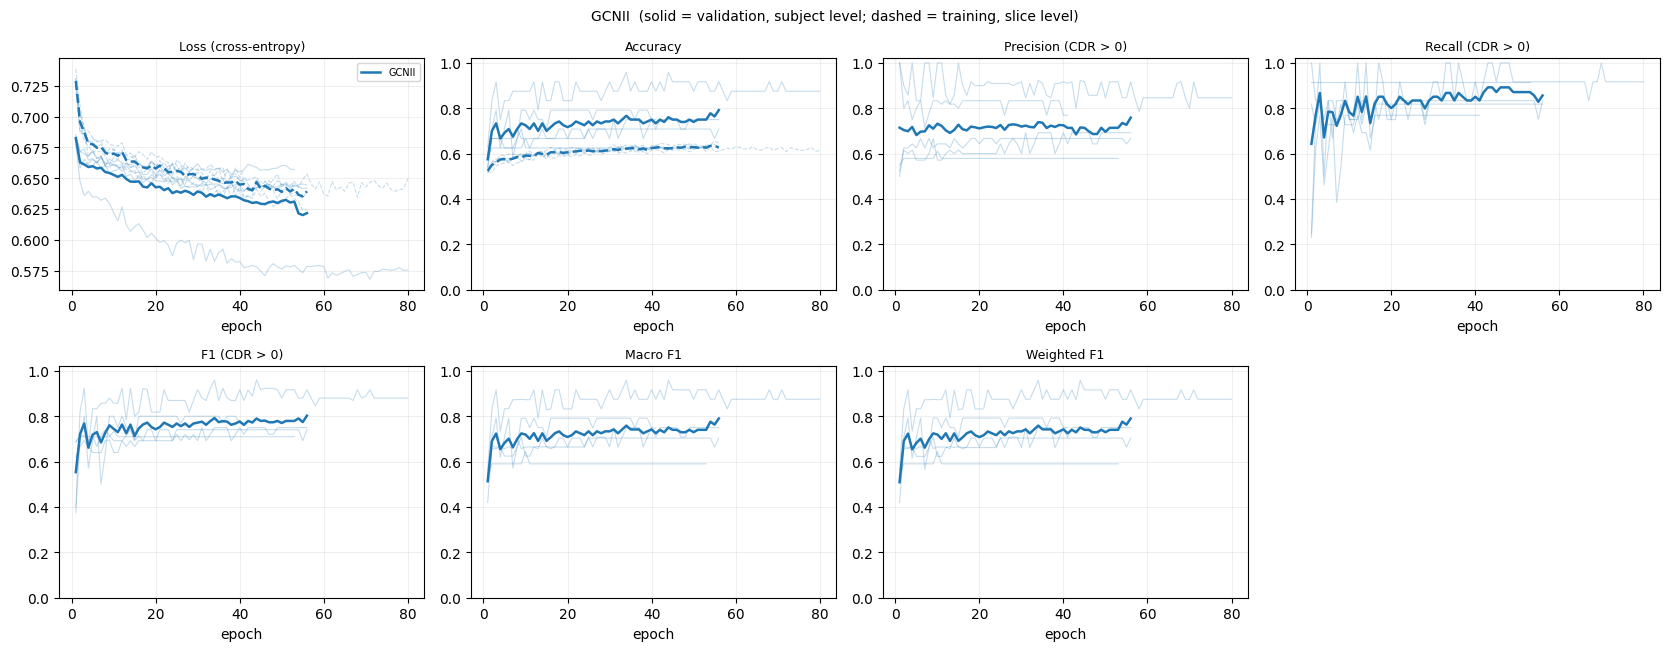

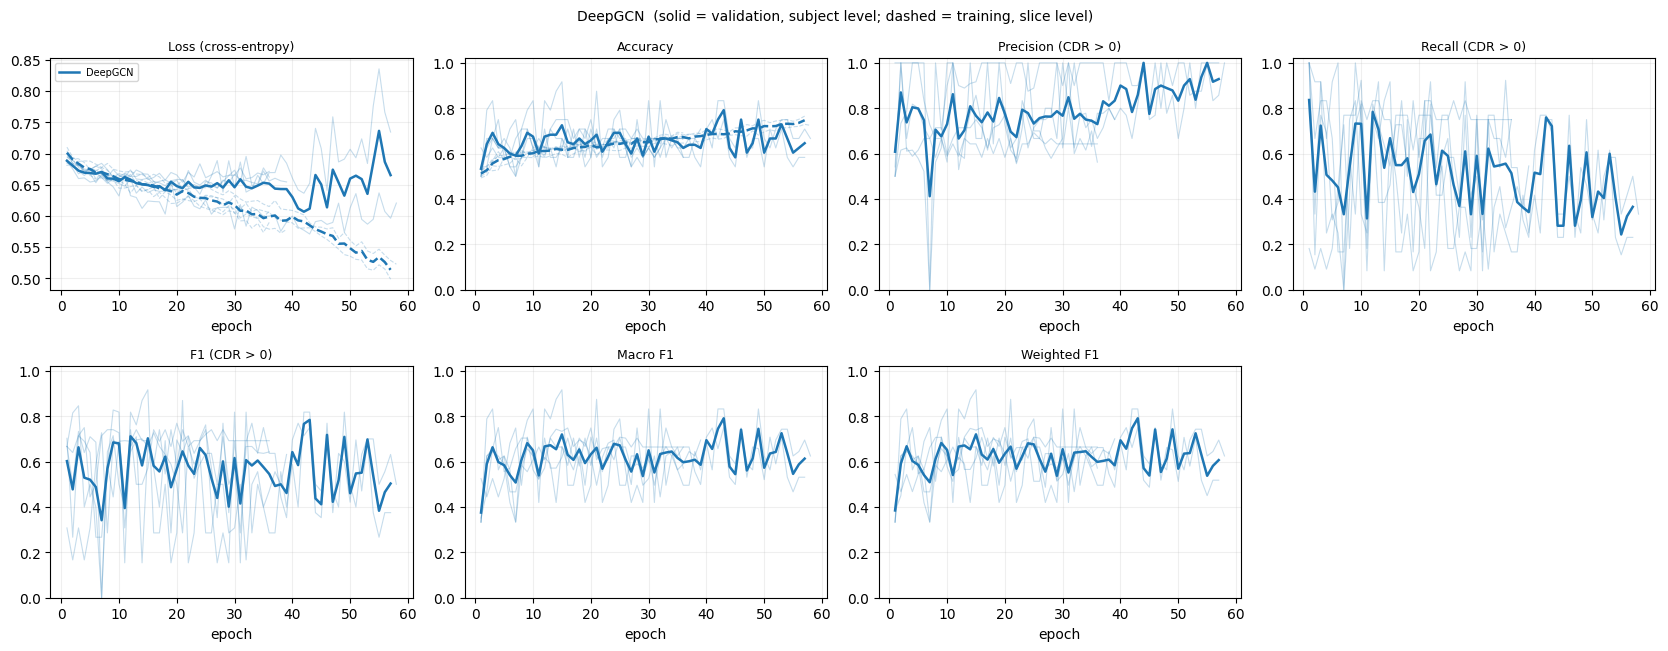

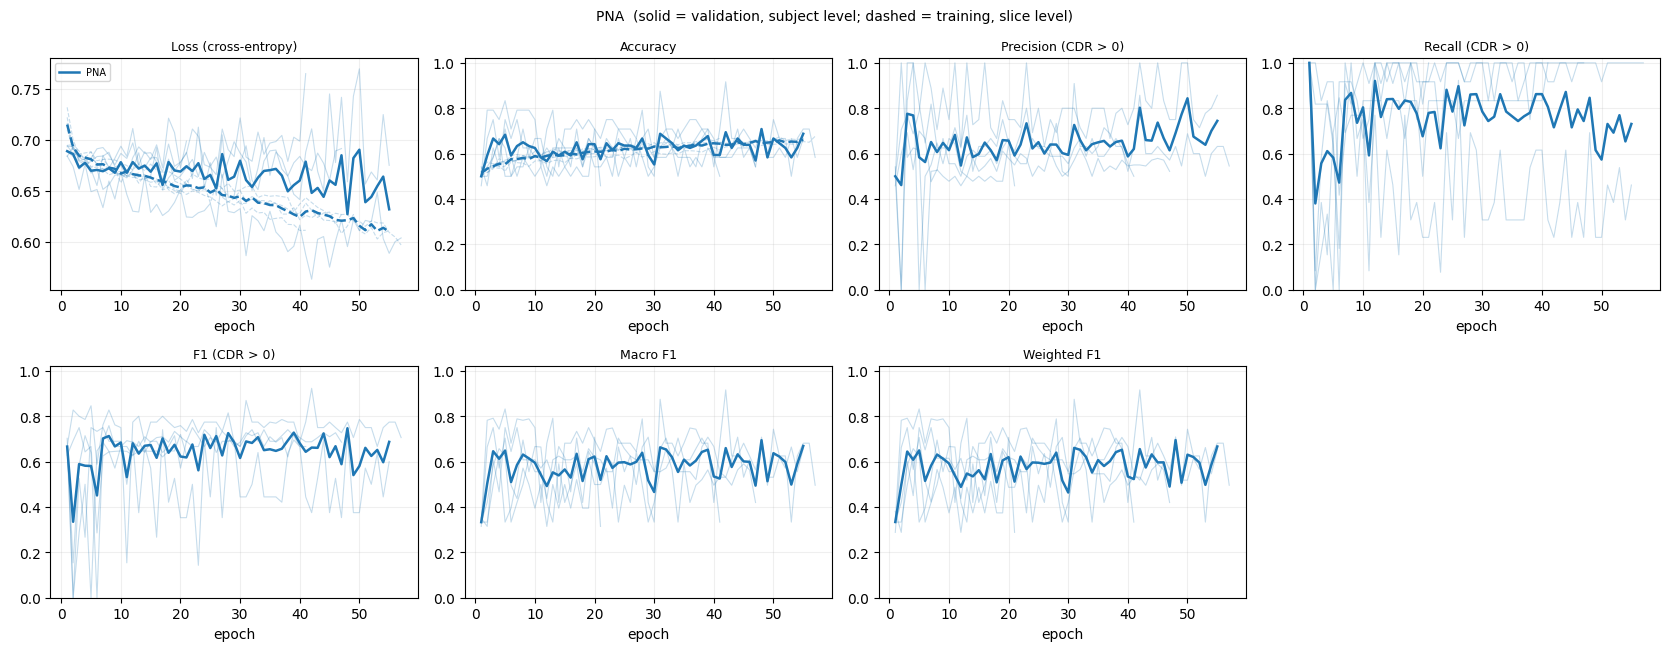

In [10]:
H = pd.concat([pd.read_csv(p) for p in sorted(OUT_DIR.glob(f"{TASK}_*_history.csv"))], ignore_index=True)
H = H[H.data_id == DATA_ID]                                    # ignore results from other data versions
assert len(H), "no history files for the current data: run section 5 first"
order_h = [m for m in GNNS if m in set(H.model)]

HIST_METRICS = [("val_loss", "Loss (cross-entropy)", "train_loss"),
                ("val_acc", "Accuracy", "train_acc"),
                ("val_precision", "Precision (CDR > 0)" if N_CLASSES == 2 else "Precision (macro)", None),
                ("val_recall", "Recall (CDR > 0)" if N_CLASSES == 2 else "Recall (macro)", None)]
if N_CLASSES == 2:
    HIST_METRICS.append(("val_f1", "F1 (CDR > 0)", None))
HIST_METRICS += [("val_f1_macro", "Macro F1", None), ("val_f1_weighted", "Weighted F1", None)]

def curves_grid(H, models, per_fold, fname, title):
    ncols = 4; nrows = int(np.ceil(len(HIST_METRICS) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.3 * nrows)); axes = axes.ravel()
    for ax, (col, ttl, tcol) in zip(axes, HIST_METRICS):
        for i, m in enumerate(models):
            d, c = H[H.model == m], f"C{i}"
            if per_fold:
                for _, dk in d.groupby("fold"):
                    ax.plot(dk.epoch, dk[col], c=c, alpha=0.25, lw=0.8)
                    if tcol: ax.plot(dk.epoch, dk[tcol], c=c, alpha=0.25, lw=0.8, ls="--")
            need = min(2, d.fold.nunique())                      # mean only where at least 2 folds are still training
            for column, ls, lab in [(col, "-", m)] + ([(tcol, "--", None)] if tcol else []):
                g = d.groupby("epoch")[column]
                mean = g.mean()[g.count() >= need]
                ax.plot(mean.index, mean.values, c=c, lw=1.8, ls=ls, label=lab)
        ax.set_title(ttl, fontsize=9); ax.set_xlabel("epoch"); ax.grid(alpha=0.2)
        if col != "val_loss": ax.set_ylim(0, 1.02)
    for ax in axes[len(HIST_METRICS):]: ax.axis("off")
    axes[0].legend(fontsize=7)
    fig.suptitle(title + "  (solid = validation, subject level; dashed = training, slice level)", fontsize=10)
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=150); plt.show()

for gname, ms in by_group(order_h):
    curves_grid(H, ms, False, f"{TASK}_curves_{gname.replace(' ', '_')}.png", f"{gname}, mean over folds")
for m in order_h:
    curves_grid(H, [m], True, f"{TASK}_curves_{m.replace('/', '-').replace(' ', '_')}.png", m)
H.to_csv(OUT_DIR / f"{TASK}_training_history_all.csv", index=False)

## 6. Results

Tables and plots are split by group (Classic GNNs, Modern GNNs).

Mean and standard deviation over the 5 test folds, on subject-level predictions. The dashed line is the best tabular baseline (age + nWBV).

In [11]:
res = pd.DataFrame([json.load(open(p)) for p in sorted(OUT_DIR.glob(f"{TASK}_*_fold*.json"))])
if "data_id" not in res.columns: res["data_id"] = None
res = res[res.data_id == DATA_ID]                              # ignore results from other data versions
assert len(res), "no results for the current data: run the previous cell first"
order = [m for m in GNNS if m in set(res.model)]
cols = ["auc", "bal_acc", "acc", "f1"] + (["sens", "spec"] if N_CLASSES == 2 else [])

agg = res.groupby("model")[cols].agg(["mean", "std"]).loc[order]
summary = pd.DataFrame({"model": order})
for c in cols:
    summary[c] = [f"{agg.loc[m, (c, 'mean')]:.3f} \u00b1 {agg.loc[m, (c, 'std')]:.3f}" for m in order]
info = res.groupby("model").agg(params_k=("n_params_k", "first"), min_per_fold=("minutes", "mean"),
                                best_epoch=("best_epoch", "mean")).loc[order]
summary = summary.merge(info.reset_index(), on="model")
summary.insert(1, "group", summary.model.map(GROUP_OF))
for gname, ms in by_group(order):
    print(f"\n--- {gname} ---")
    print(summary[summary.model.isin(ms)].drop(columns="group").round(2).to_string(index=False))
summary.to_csv(OUT_DIR / f"{TASK}_gnn_baselines_summary.csv", index=False)

print("\nAUC per fold:")
print(res.pivot(index="model", columns="fold", values="auc").loc[order].round(3))

ref = None
tab = DATA_DIR / "tabular_baselines.csv"
if tab.exists() and TASK == "binary":
    t = pd.read_csv(tab); ref = float(t.loc[t.features == "Age + nWBV", "auc_mean"].iloc[0])
    print(f"\nTabular reference (Age + nWBV) AUC: {ref:.3f}")


--- Classic GNNs ---
    model           auc       bal_acc           acc            f1          sens          spec  params_k  min_per_fold  best_epoch
      GCN 0.715 ± 0.048 0.637 ± 0.053 0.626 ± 0.060 0.620 ± 0.077 0.623 ± 0.138 0.650 ± 0.104      17.5          0.28        26.0
GraphSAGE 0.701 ± 0.069 0.653 ± 0.048 0.651 ± 0.048 0.677 ± 0.050 0.734 ± 0.040 0.571 ± 0.065      26.1          0.28        38.0
    GATv2 0.709 ± 0.053 0.646 ± 0.054 0.636 ± 0.063 0.637 ± 0.054 0.644 ± 0.113 0.648 ± 0.101      26.7          0.34        25.6
  ChebNet 0.703 ± 0.056 0.673 ± 0.045 0.676 ± 0.052 0.699 ± 0.064 0.756 ± 0.031 0.589 ± 0.099      34.7          0.42        34.4
      ViG 0.691 ± 0.053 0.634 ± 0.080 0.621 ± 0.088 0.616 ± 0.082 0.617 ± 0.147 0.650 ± 0.177    1440.3          1.44        17.4

--- Modern GNNs ---
          model           auc       bal_acc           acc            f1          sens          spec  params_k  min_per_fold  best_epoch
            GIN 0.699 ± 0.057 0.648 ± 0.0

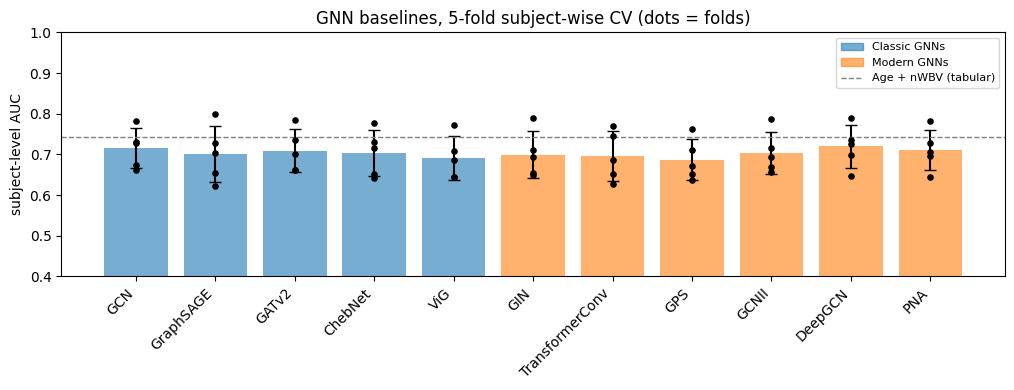

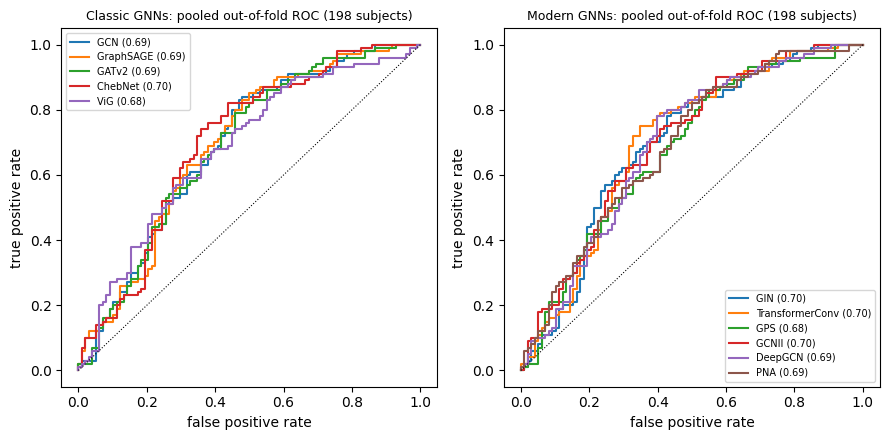

In [12]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(max(7, 0.75 * len(order) + 2), 4))
for i, m in enumerate(order):
    v = res.loc[res.model == m].sort_values("fold").auc.values
    ax.bar(i, v.mean(), yerr=v.std(ddof=1) if len(v) > 1 else 0, alpha=0.6, capsize=4, color=GROUP_COLORS[GROUP_OF[m]])
    ax.scatter(np.full(len(v), i), v, c="k", s=14, zorder=3)
if ref is not None:
    ax.axhline(ref, ls="--", c="grey", lw=1, label="Age + nWBV (tabular)")
h0, _ = ax.get_legend_handles_labels()
ax.legend(handles=[Patch(color=GROUP_COLORS[g], alpha=0.6, label=g) for g, _ in by_group(order)] + h0, fontsize=8)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=45, ha="right")
ax.set_ylabel("subject-level AUC"); ax.set_ylim(0.4, 1.0)
ax.set_title("GNN baselines, 5-fold subject-wise CV (dots = folds)")
plt.tight_layout(); plt.savefig(OUT_DIR / f"{TASK}_gnn_auc_by_model.png", dpi=150); plt.show()

if N_CLASSES == 2:
    oof = pd.concat([pd.read_csv(p) for p in sorted(OUT_DIR.glob(f"{TASK}_*_preds.csv"))])
    grp = by_group(order)
    fig, axs = panel_axes(len(grp), w=4.5, h=4.5)
    for ax, (gname, ms) in zip(axs, grp):
        for m in ms:
            d = oof[oof.model == m]
            fpr, tpr, _ = roc_curve(d.y, d.p1)
            ax.plot(fpr, tpr, label=f"{m} ({roc_auc_score(d.y, d.p1):.2f})")
        ax.plot([0, 1], [0, 1], "k:", lw=0.8)
        ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
        ax.set_title(f"{gname}: pooled out-of-fold ROC (198 subjects)", fontsize=9); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(OUT_DIR / f"{TASK}_gnn_roc_pooled.png", dpi=150); plt.show()

## 6b. Precision, recall, F1 and the classification report

Computed from the **subject-level out-of-fold predictions** saved in section 5 (`*_preds.csv`), with the same decision rule as `metrics()` (binary: p1 >= 0.5, three-class: argmax).

- **Table:** precision, recall, macro F1 and weighted F1 per fold, then mean ± std over the 5 folds (same style as section 6). In the binary task, precision and recall are for the positive class (CDR > 0). Macro averages every class equally, weighted averages by class size.
- **Classification report:** one per model, on all subjects pooled over the 5 test folds.

In [13]:
from sklearn.metrics import (precision_score, recall_score, classification_report,
                             precision_recall_curve, average_precision_score)

CLASS_NAMES = ["CDR 0", "CDR > 0"] if N_CLASSES == 2 else ["CDR 0", "CDR 0.5", "CDR 1+"]
LABELS = list(range(N_CLASSES))
PCOLS = [f"p{c}" for c in range(N_CLASSES)]

# out-of-fold subject predictions saved in section 5 (one row per subject and model)
oof_g = pd.concat([pd.read_csv(p) for p in sorted(OUT_DIR.glob(f"{TASK}_*_preds.csv"))], ignore_index=True)
oof_g = oof_g[oof_g.model.isin(order)]

def hard_pred(d):
    P = d[PCOLS].values
    return (P[:, 1] >= 0.5).astype(int) if N_CLASSES == 2 else P.argmax(1)     # same rule as metrics()

# ---- per fold ----
rows = []
for (m, k), d in oof_g.groupby(["model", "fold"]):
    yt, yh = d.y.values, hard_pred(d)
    r = dict(model=m, fold=k)
    if N_CLASSES == 2:                                         # positive class = CDR > 0
        r["precision"] = precision_score(yt, yh, pos_label=1, zero_division=0)
        r["recall"]    = recall_score(yt, yh, pos_label=1, zero_division=0)
    r["precision_macro"] = precision_score(yt, yh, labels=LABELS, average="macro", zero_division=0)
    r["recall_macro"]    = recall_score(yt, yh, labels=LABELS, average="macro", zero_division=0)
    r["f1_macro"]        = f1_score(yt, yh, labels=LABELS, average="macro", zero_division=0)
    r["f1_weighted"]     = f1_score(yt, yh, labels=LABELS, average="weighted", zero_division=0)
    rows.append(r)
fold_m = pd.DataFrame(rows)
fold_m.insert(1, "group", fold_m.model.map(GROUP_OF))
fold_m.to_csv(OUT_DIR / f"{TASK}_gnn_prf_per_fold.csv", index=False)

# ---- mean ± std over folds ----
mcols = [c for c in fold_m.columns if c not in ("model", "group", "fold")]
agg2 = fold_m.groupby("model")[mcols].agg(["mean", "std"]).loc[order]
prf = pd.DataFrame({"model": order})
prf.insert(1, "group", prf.model.map(GROUP_OF))
for c in mcols:
    prf[c] = [f"{agg2.loc[m, (c, 'mean')]:.3f} \u00b1 {agg2.loc[m, (c, 'std')]:.3f}" for m in order]
print("Mean \u00b1 std over the test folds (subject level):")
for gname, ms in by_group(order):
    print(f"\n--- {gname} ---")
    print(prf[prf.model.isin(ms)].drop(columns="group").to_string(index=False))
prf.to_csv(OUT_DIR / f"{TASK}_gnn_prf_summary.csv", index=False)

# ---- pooled classification report, one per model ----
print("\nClassification report, all test subjects pooled over the folds")
texts = []
for gname, ms in by_group(order):
    for m in ms:
        d = oof_g[oof_g.model == m].sort_values("subject")
        txt = classification_report(d.y.values, hard_pred(d), labels=LABELS, target_names=CLASS_NAMES,
                                    digits=3, zero_division=0)
        texts.append(f"=== {gname} | {m} ===\n{txt}")
        print(f"\n=== {gname} | {m} ===\n{txt}")
(OUT_DIR / f"{TASK}_gnn_classification_reports.txt").write_text("\n".join(texts))

Mean ± std over the test folds (subject level):

--- Classic GNNs ---
    model     precision        recall precision_macro  recall_macro      f1_macro   f1_weighted
      GCN 0.644 ± 0.097 0.623 ± 0.138   0.638 ± 0.052 0.637 ± 0.053 0.624 ± 0.062 0.625 ± 0.062
GraphSAGE 0.635 ± 0.085 0.734 ± 0.040   0.654 ± 0.049 0.653 ± 0.048 0.646 ± 0.051 0.651 ± 0.048
    GATv2 0.651 ± 0.092 0.644 ± 0.113   0.647 ± 0.056 0.646 ± 0.054 0.635 ± 0.063 0.637 ± 0.061
  ChebNet 0.654 ± 0.096 0.756 ± 0.031   0.677 ± 0.044 0.673 ± 0.045 0.668 ± 0.050 0.674 ± 0.052
      ViG 0.654 ± 0.129 0.617 ± 0.147   0.638 ± 0.083 0.634 ± 0.080 0.617 ± 0.089 0.618 ± 0.090

--- Modern GNNs ---
          model     precision        recall precision_macro  recall_macro      f1_macro   f1_weighted
            GIN 0.629 ± 0.094 0.725 ± 0.110   0.655 ± 0.045 0.648 ± 0.037 0.643 ± 0.040 0.649 ± 0.046
TransformerConv 0.663 ± 0.077 0.753 ± 0.055   0.684 ± 0.039 0.678 ± 0.041 0.676 ± 0.042 0.684 ± 0.042
            GPS 0.619 ± 0.1

3917

## 6c. Precision-recall curve

Pooled out-of-fold subject probabilities, one curve per model. AP is average precision (area under the PR curve). The dotted line is a model with no skill, which sits at the share of positive subjects. The binary task has one plot (positive class = CDR > 0); the three-class task has one plot per class (one-vs-rest).

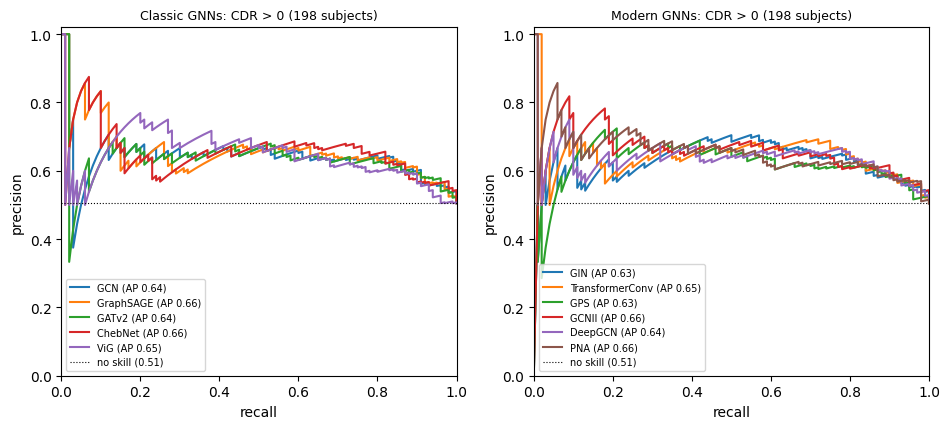

Average precision (pooled out-of-fold):

--- Classic GNNs ---
positive_class  CDR > 0
model                  
GCN               0.643
GraphSAGE         0.660
GATv2             0.638
ChebNet           0.660
ViG               0.649

--- Modern GNNs ---
positive_class   CDR > 0
model                   
GIN                0.632
TransformerConv    0.649
GPS                0.625
GCNII              0.660
DeepGCN            0.642
PNA                0.657


In [14]:
classes = [1] if N_CLASSES == 2 else LABELS
grp = by_group(order)
ap_rows = []
for c in classes:
    fig, axs = panel_axes(len(grp))
    for ax, (gname, ms) in zip(axs, grp):
        for m in ms:
            d = oof_g[oof_g.model == m]
            yb, sc = (d.y.values == c).astype(int), d[f"p{c}"].values
            pr, rc, _ = precision_recall_curve(yb, sc)
            ap = average_precision_score(yb, sc)
            ax.plot(rc, pr, label=f"{m} (AP {ap:.2f})")
            ap_rows.append(dict(model=m, positive_class=CLASS_NAMES[c], AP=ap))
        ax.axhline(yb.mean(), ls=":", c="k", lw=0.8, label=f"no skill ({yb.mean():.2f})")
        ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
        ax.set_title(f"{gname}: {CLASS_NAMES[c]} ({len(d)} subjects)", fontsize=9)
        ax.legend(fontsize=7, loc="lower left")
    plt.tight_layout()
    plt.savefig(OUT_DIR / (f"{TASK}_gnn_pr_pooled" + ("" if N_CLASSES == 2 else f"_class{c}") + ".png"), dpi=150)
    plt.show()

ap_tab = pd.DataFrame(ap_rows).pivot(index="model", columns="positive_class", values="AP").loc[order]
ap_tab.insert(0, "group", ap_tab.index.map(GROUP_OF))
print("Average precision (pooled out-of-fold):")
for gname, ms in by_group(order):
    print(f"\n--- {gname} ---")
    print(ap_tab.loc[ms].drop(columns="group").round(3).to_string())
ap_tab.round(4).to_csv(OUT_DIR / f"{TASK}_gnn_average_precision.csv")

## 6d. Model size and inference time

- **Size:** parameter count, and the size of the saved weights (`state_dict`, float32, includes BatchNorm statistics).
- **Inference time:** forward pass only, in eval mode with `torch.no_grad()`, median of 30 runs after 5 warm-up runs, on the device printed below. Inputs are already on the device, so data transfer is not counted. Timing does not depend on the weight values, so freshly initialised models are timed (no trained weights needed). Times are measured with 1 slice and with a batch of 64 slices. The per-subject time is the batched time per slice multiplied by the average number of slices per subject.
- **Graph building:** every superpixel-graph model needs a SLIC graph for every slice at test time (CPU). ViG does not. That cost is listed separately and added in the last column, so the comparison is fair.

In [15]:
import io
from torch_geometric.data import Batch

def state_dict_mb(model):
    buf = io.BytesIO(); torch.save(model.state_dict(), buf)
    return buf.getbuffer().nbytes / 1e6

def sync():
    if device.type == "cuda": torch.cuda.synchronize()

def time_ms(fn, warmup=5, reps=30):
    for _ in range(warmup): fn()
    sync(); ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); sync()
        ts.append((time.perf_counter() - t0) * 1e3)
    return float(np.median(ts))

BIG = 64
pick = np.random.default_rng(SEED).choice(len(graphs), BIG, replace=False)      # fixed random slices
gb1, gbN = Batch.from_data_list([graphs[pick[0]]]).to(device), Batch.from_data_list([graphs[i] for i in pick]).to(device)
xb1, xbN = X_t[pick[:1]].unsqueeze(1).to(device), X_t[pick].unsqueeze(1).to(device)   # X_t is built in section 4
slices_per_subject = len(meta) / meta.subject.nunique()

t0 = time.perf_counter()                                                            # SLIC graph building, CPU, 20 slices
for i in pick[:20]:
    slice_to_graph_np(X[i], int(meta.slice_idx.iloc[i]))
build_ms = (time.perf_counter() - t0) / 20 * 1e3

print(f"device: {device} | {slices_per_subject:.1f} slices per subject | graph building {build_ms:.1f} ms per slice (CPU)\n")

cost = []
for name, kind in GNNS.items():
    seed_all(SEED)
    model = (make_vig() if kind == "vig" else make_gnn(kind, DEG_ALL)).to(device).eval()
    if kind == "vig":
        def run(x):
            with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                return model(vig_prep(x))
        t1, tN, build = time_ms(lambda: run(xb1)), time_ms(lambda: run(xbN)), 0.0
    else:
        def run(b):
            with torch.no_grad():
                return model(b.x, b.edge_index, b.batch)
        t1, tN, build = time_ms(lambda: run(gb1)), time_ms(lambda: run(gbN)), build_ms
    cost.append(dict(model=name, group=GROUP_OF[name],
                     params_k=sum(p.numel() for p in model.parameters()) / 1e3,
                     weights_MB=state_dict_mb(model),
                     ms_per_slice_batch1=t1,
                     ms_per_slice_batch64=tN / BIG,
                     ms_per_subject_model=tN / BIG * slices_per_subject,
                     graph_build_ms_per_slice=build,
                     ms_per_subject_total=(tN / BIG + build) * slices_per_subject))
    del model
    if device.type == "cuda": torch.cuda.empty_cache()

cost = pd.DataFrame(cost).set_index("model")
for gname, ms in by_group(list(cost.index)):
    print(f"\n--- {gname} ---")
    print(cost.loc[ms].drop(columns="group").round(2).to_string())
cost.round(4).to_csv(OUT_DIR / f"{TASK}_gnn_model_cost.csv")

device: cuda | 17.0 slices per subject | graph building 31.4 ms per slice (CPU)


--- Classic GNNs ---
           params_k  weights_MB  ms_per_slice_batch1  ms_per_slice_batch64  ms_per_subject_model  graph_build_ms_per_slice  ms_per_subject_total
model                                                                                                                                           
GCN           17.54        0.08                 2.72                  0.05                  0.79                     31.35                533.74
GraphSAGE     26.11        0.12                 1.73                  0.03                  0.48                     31.35                533.43
GATv2         26.69        0.12                 3.73                  0.09                  1.50                     31.35                534.45
ChebNet       34.69        0.15                 5.13                  0.08                  1.31                     31.35                534.26
ViG         1440.26        

## 6e. UMAP of the best models

**What is plotted.** For each test subject, the model's *embedding* is the vector it gives to its last layer (for the image models, the pooled features before the final classifier; for the graph models, the mean + max readout of the nodes), averaged over the subject's slices. UMAP squeezes these long vectors into 2 dimensions so you can look at them. Colour is the true class. A round dot is a subject the model got right (0.5 / argmax rule), and a cross is one it got wrong.

**How to read it, and what not to read into it**
- Each of the 5 folds has its own trained model, so each fold has its **own embedding space**. The 5 panels cannot be laid on top of each other, and there is no single UMAP for all 198 subjects.
- Only the **test subjects of that fold** are shown (about 40), which the model never saw in training. With so few points, UMAP shapes are unstable: treat clusters as a hint, not as proof.
- The axes have no units, and distances between far-apart groups mean little. Close points are similar to the model.
- The silhouette number is computed on the full embedding (cosine distance), not on the 2D picture. It runs from -1 to 1: near 0 means the classes overlap, higher means the classes are better separated.

**Best models** are the top `UMAP_TOP` by mean test AUC (set `UMAP_MODELS = ["name", ...]` to choose yourself). The embeddings are saved during training (`*_emb.npz`, setting `SAVE_EMBEDDINGS`), because the trained weights themselves are not kept.

Models plotted (mean test AUC): DeepGCN (0.719), GCN (0.715), PNA (0.711)
55 embedding files | models: ['ChebNet', 'DeepGCN', 'GATv2', 'GCN', 'GCNII', 'GIN', 'GPS', 'GraphSAGE', 'PNA', 'TransformerConv', 'ViG']


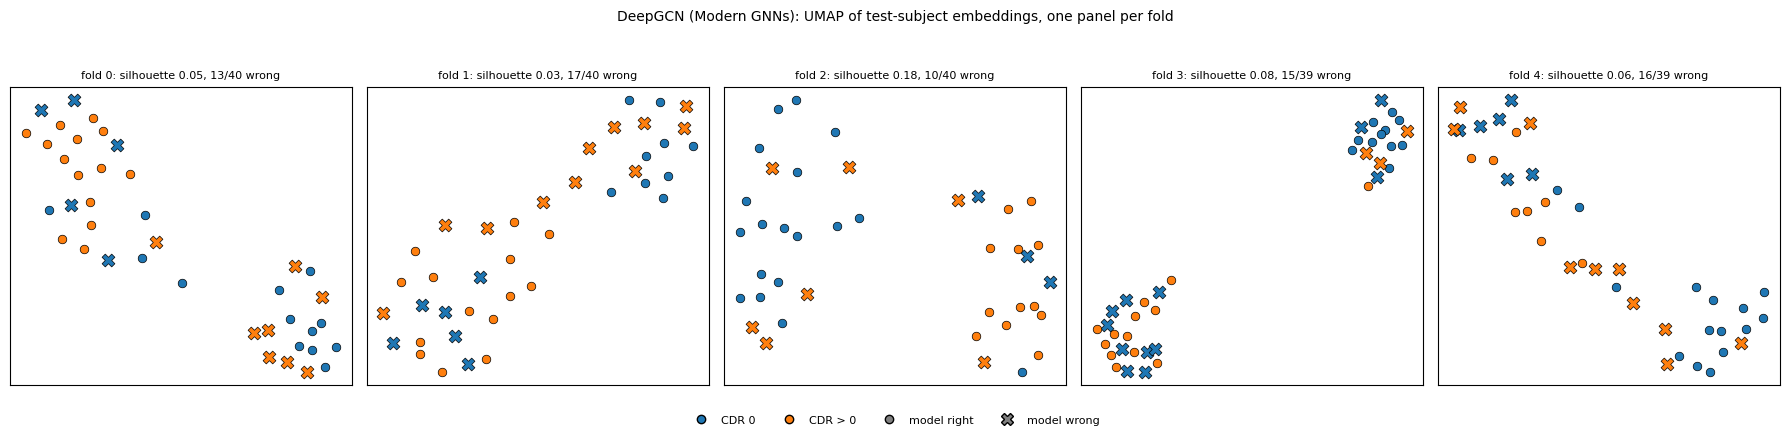

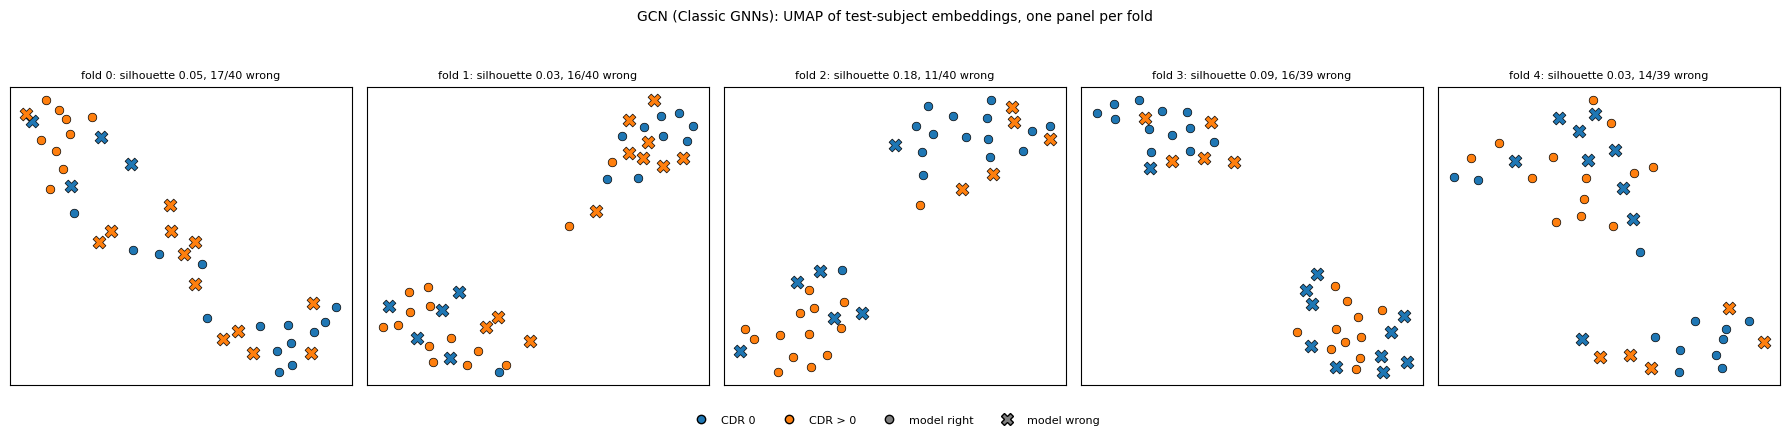

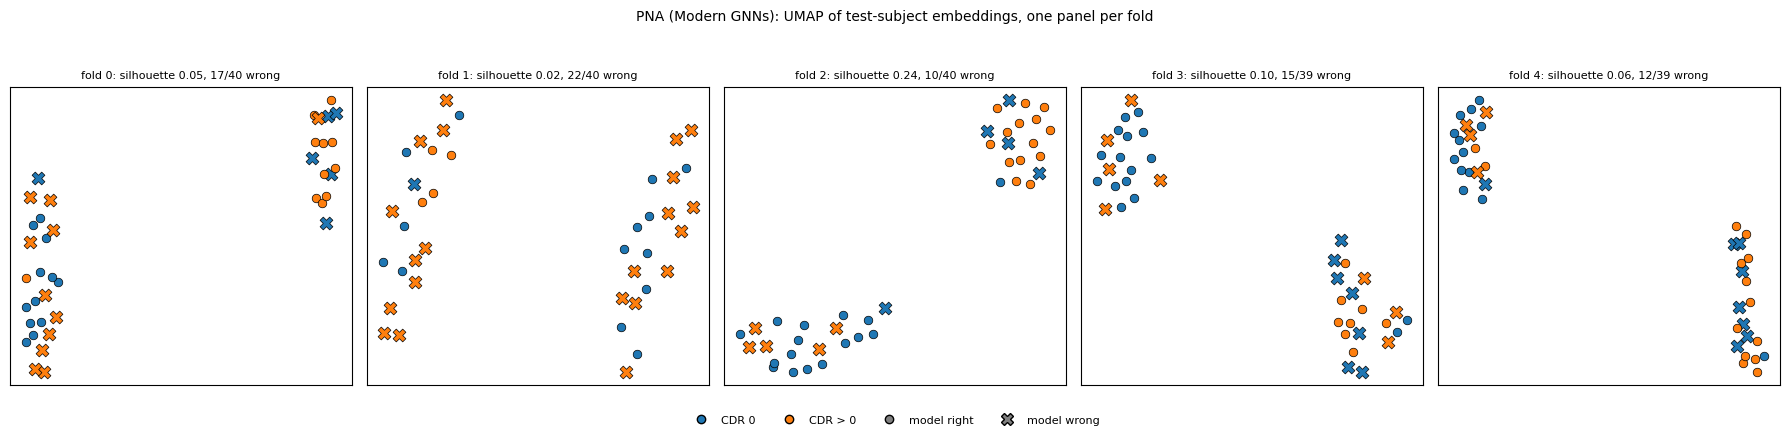

Class separation in the embedding (silhouette, mean ± std over folds):
            silhouette
model                 
DeepGCN  0.079 ± 0.056
GCN      0.077 ± 0.065
PNA      0.097 ± 0.087


In [16]:
UMAP_TOP = 3                    # how many best models (by mean test AUC) to plot
UMAP_MODELS = None              # or choose by name, for example ["ConvNeXt V2", "Swin"]
UMAP_NEIGHBORS, UMAP_MIN_DIST = 8, 0.3     # small neighbourhood, because each fold has only about 40 test subjects

mean_auc = res.groupby("model").auc.mean().sort_values(ascending=False)
BEST = list(UMAP_MODELS) if UMAP_MODELS else list(mean_auc.index[:UMAP_TOP])
print("Models plotted (mean test AUC):", ", ".join(f"{m} ({mean_auc.get(m, float('nan')):.3f})" for m in BEST))
EMB_FILES = sorted(OUT_DIR.glob(f"{TASK}_*_emb.npz"))

import sys, subprocess
try:
    import umap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "umap-learn"])
    import umap
from matplotlib.lines import Line2D
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

EMB = {}
for p in EMB_FILES:
    z = np.load(p, allow_pickle=True)
    EMB[(str(z["model"]), int(z["fold"]))] = (z["subject"], z["emb"])
print(f"{len(EMB)} embedding files | models: {sorted({m for m, _ in EMB})}")

sil_rows = []
for m in BEST:
    ks = sorted(k for (mm, k) in EMB if mm == m)
    if not ks:
        print(f"{m}: no embedding files found (they are saved while training, see SAVE_EMBEDDINGS), so it is skipped")
        continue
    fig, axs = plt.subplots(1, len(ks), figsize=(3.6 * len(ks), 4.3), squeeze=False)
    for ax, k in zip(axs[0], ks):
        subj, Xe = EMB[(m, k)]
        d = oof_g[(oof_g.model == m) & (oof_g.fold == k)].set_index("subject").loc[subj]
        y, wrong = d.y.values, hard_pred(d) != d.y.values
        Z = StandardScaler().fit_transform(Xe)
        xy = umap.UMAP(n_neighbors=max(2, min(UMAP_NEIGHBORS, len(subj) - 1)), min_dist=UMAP_MIN_DIST,
                       metric="cosine", random_state=SEED).fit_transform(Z)
        for c in LABELS:
            for flag, mk, sz in ((False, "o", 38), (True, "X", 85)):
                s = (y == c) & (wrong == flag)
                ax.scatter(xy[s, 0], xy[s, 1], c=f"C{c}", marker=mk, s=sz, edgecolors="k", linewidths=0.5)
        sil = silhouette_score(Z, y, metric="cosine") if len(np.unique(y)) >= 2 else np.nan
        sil_rows.append(dict(model=m, fold=k, n_subjects=len(subj), n_wrong=int(wrong.sum()), silhouette=sil))
        ax.set_title(f"fold {k}: silhouette {sil:.2f}, {int(wrong.sum())}/{len(subj)} wrong", fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
    handles = [Line2D([], [], marker="o", ls="", color=f"C{c}", markeredgecolor="k", label=CLASS_NAMES[c]) for c in LABELS]
    handles += [Line2D([], [], marker="o", ls="", color="grey", markeredgecolor="k", label="model right"),
                Line2D([], [], marker="X", ls="", color="grey", markeredgecolor="k", markersize=9, label="model wrong")]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), fontsize=8, frameon=False)
    fig.suptitle(f"{m} ({GROUP_OF.get(m, '')}): UMAP of test-subject embeddings, one panel per fold", fontsize=10)
    plt.tight_layout(rect=[0, 0.07, 1, 0.94])
    plt.savefig(OUT_DIR / f"{TASK}_umap_{m.replace('/', '-').replace(' ', '_')}.png", dpi=150); plt.show()

if sil_rows:
    sil_df = pd.DataFrame(sil_rows)
    sil_df.to_csv(OUT_DIR / f"{TASK}_umap_silhouette.csv", index=False)
    s = sil_df.groupby("model").silhouette.agg(["mean", "std"]).loc[[m for m in BEST if m in set(sil_df.model)]]
    print("Class separation in the embedding (silhouette, mean \u00b1 std over folds):")
    print(pd.DataFrame({"silhouette": [f"{r['mean']:.3f} \u00b1 {r['std']:.3f}" for _, r in s.iterrows()]}, index=s.index).to_string())

## 7. Side by side with the image baselines

If the image-baselines notebook has been run (results in `CNN_DIR`), this combines both sets of fold results on the same folds, sorted by mean AUC. The folds and subjects are identical, so the comparison is paired by fold.

In [17]:
# search CNN_DIR and its subfolders (a mounted notebook output keeps the results in a "baselines" subfolder)
cnn_files = sorted(CNN_DIR.rglob(f"{TASK}_*_fold*.json")) if CNN_DIR.exists() else []
cnn_files = [p for p in cnn_files if "smoke" not in str(p) and not p.name.endswith("_run_config.json")]
print(f"image-baseline result files found: {len(cnn_files)} (in {CNN_DIR})")
if not cnn_files:
    print("None found. Check that CNN_DIR points at the folder that contains the *_fold*.json files; "
          "run `list(CNN_DIR.rglob('*.json'))[:5]` to see what is there.")
else:
    a = res.assign(family=[("ViG (image-patch graph)" if m == "ViG" else f"{GROUP_OF[m]} (superpixel graph)") for m in res.model])
    b = pd.DataFrame([json.load(open(p)) for p in cnn_files])
    b["family"] = (b["group"].fillna("CNN / ViT") if "group" in b.columns else "CNN / ViT") + " (slice images)"
    if "data_id" not in b.columns: b["data_id"] = None
    if (b.data_id != DATA_ID).any():
        print("WARNING: some image-baseline results come from a different data version and are left out: re-run that notebook.")
    b = b[b.data_id == DATA_ID]
    both = pd.concat([a, b], ignore_index=True)
    comb = (both.groupby(["family", "model"])[["auc", "bal_acc", "f1"]].agg(["mean", "std"]))
    comb.columns = [f"{m}_{s}" for m, s in comb.columns]
    comb = comb.sort_values("auc_mean", ascending=False).round(3)
    print(comb.to_string())
    comb.to_csv(OUT_DIR / f"{TASK}_all_baselines_summary.csv")
    if ref is not None:
        print(f"\nTabular reference (Age + nWBV) AUC: {ref:.3f}")
    best = comb.index[0]
    pv = both.pivot_table(index="fold", columns="model", values="auc")
    print(f"\nBest overall: {best[1]}. Folds where it beats each other model (AUC):")
    for m in pv.columns:
        if m != best[1]:
            print(f"  vs {m:16s} {int((pv[best[1]] > pv[m]).sum())}/{len(pv)}  mean diff {float((pv[best[1]] - pv[m]).mean()):+.3f}")

image-baseline result files found: 80 (in /kaggle/input/notebooks/stillniloy/cnn-baselines-mri/baselines)
                                                 auc_mean  auc_std  bal_acc_mean  bal_acc_std  f1_mean  f1_std
family                          model                                                                         
Transformers (slice images)     CAFormer            0.748    0.044         0.653        0.047    0.655   0.071
                                BEiT                0.746    0.049         0.659        0.107    0.548   0.314
                                ViT-B/16            0.743    0.060         0.690        0.066    0.690   0.087
                                DeiT                0.742    0.052         0.651        0.058    0.689   0.097
Classic CNNs (slice images)     DenseNet201         0.734    0.046         0.674        0.060    0.660   0.106
                                EfficientNet-B0     0.731    0.080         0.657        0.108    0.642   0.147
Transf

In [18]:
import shutil
ALL = Path("/kaggle/working/all_preds"); ALL.mkdir(exist_ok=True)
for d in [CNN_DIR, OUT_DIR]:
    for p in d.rglob(f"{TASK}_*_preds.csv"):
        if "smoke" not in str(p): shutil.copy(p, ALL / p.name)
print(len(list(ALL.glob("*.csv"))), "prediction files")   # 5 per model (one per fold)

135 prediction files


In [19]:
B = 2000
rng = np.random.default_rng(SEED)
oof = pd.concat([pd.read_csv(p) for p in sorted(ALL.glob(f"{TASK}_*_preds.csv"))])
P = oof.pivot(index="subject", columns="model", values="p1")                 # subjects x models
y = oof.drop_duplicates("subject").set_index("subject").y.loc[P.index].values
models, n = list(P.columns), len(y)

point = np.array([roc_auc_score(y, P[m].values) for m in models])             # pooled out-of-fold AUC
boot = np.empty((B, len(models)))
for b in range(B):                                                           # resample SUBJECTS with replacement
    while True:
        idx = rng.integers(0, n, n)
        if 0 < y[idx].sum() < n: break
    boot[b] = [roc_auc_score(y[idx], P[m].values[idx]) for m in models]

lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
tab = pd.DataFrame({"model": models, "pooled_AUC": point, "CI_low": lo, "CI_high": hi}).sort_values("pooled_AUC", ascending=False)
print(tab.round(3).to_string(index=False))

ref = int(np.argmax(point))                                                  # best pooled model as the reference
rows = []
for j, m in enumerate(models):
    if j == ref: continue
    d = boot[:, ref] - boot[:, j]
    rows.append(dict(reference=models[ref], other=m, diff=point[ref] - point[j],
                     CI_low=np.percentile(d, 2.5), CI_high=np.percentile(d, 97.5),
                     p_two_sided=min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))))
print("\nPaired bootstrap, same resampled subjects for both models:")
print(pd.DataFrame(rows).round(3).to_string(index=False))

          model  pooled_AUC  CI_low  CI_high
           DeiT       0.736   0.663    0.798
    DenseNet201       0.736   0.663    0.802
       ViT-B/16       0.733   0.660    0.799
       CAFormer       0.733   0.662    0.798
           BEiT       0.728   0.656    0.795
    MobileNetV2       0.715   0.639    0.788
  InceptionNeXt       0.714   0.640    0.780
       ResNet50       0.711   0.638    0.780
           Swin       0.711   0.635    0.778
EfficientNet-B0       0.710   0.636    0.779
          GCNII       0.702   0.626    0.772
TransformerConv       0.701   0.626    0.772
       RepLKNet       0.701   0.627    0.769
        ChebNet       0.701   0.625    0.772
            GIN       0.695   0.619    0.766
      GraphSAGE       0.694   0.618    0.766
        DeepGCN       0.691   0.617    0.760
            GCN       0.690   0.614    0.760
            PNA       0.688   0.612    0.759
          GATv2       0.686   0.610    0.758
         MaxViT       0.686   0.608    0.761
          

In [20]:
pf = pd.concat([pd.read_csv(p) for p in sorted(ALL.glob(f"{TASK}_*_preds.csv"))])
fold_auc = pf.groupby(["model", "fold"]).apply(lambda d: roc_auc_score(d.y, d.p1)).unstack()
fold_auc["mean"] = fold_auc.mean(axis=1)
print(fold_auc.round(3).sort_values("mean", ascending=False))

fold                 0      1      2      3      4   mean
model                                                    
CAFormer         0.745  0.776  0.799  0.739  0.683  0.748
BEiT             0.682  0.768  0.815  0.734  0.730  0.746
ViT-B/16         0.727  0.784  0.825  0.679  0.701  0.743
DeiT             0.732  0.765  0.820  0.696  0.698  0.742
DenseNet201      0.674  0.757  0.792  0.742  0.704  0.734
MaxViT           0.707  0.779  0.744  0.704  0.722  0.731
EfficientNet-B0  0.679  0.739  0.835  0.774  0.630  0.731
ResNet50         0.753  0.677  0.797  0.704  0.717  0.730
RepLKNet         0.684  0.765  0.820  0.707  0.646  0.724
MobileNetV2      0.725  0.749  0.742  0.736  0.664  0.723
Swin             0.707  0.728  0.777  0.707  0.690  0.722
DeepGCN          0.725  0.648  0.789  0.736  0.698  0.719
GCN              0.730  0.675  0.782  0.728  0.661  0.715
InceptionNeXt    0.727  0.709  0.802  0.698  0.635  0.714
NFNet            0.677  0.707  0.779  0.698  0.693  0.711
PNA           

198 subjects, 27 models. Number of models that get each subject wrong (0.5 cutoff):
n_wrong   0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16  18  19  21  22  23  24  25  26  27
subjects  34  31  10   9  11   6   4   6   6   3   6   7   3   1   2   1   3   5   1   7   1   7   6   6  10  12

By CDR group:
           subjects  share_of_models_wrong  consensus_error  wrong_in_all  wrong_in_90pct
cdr_group                                                                                
CDR 0            98                   0.36             0.35             5              19
CDR 0.5          70                   0.42             0.34             7              15
CDR 1            28                   0.20             0.11             0               0
CDR 2             2                   0.04             0.00             0               0

Among demented subjects, the models' average is wrong for 34% of CDR 0.5 (70 subjects) vs 10% of CDR 1+ (30 subjects); Fisher exact p 

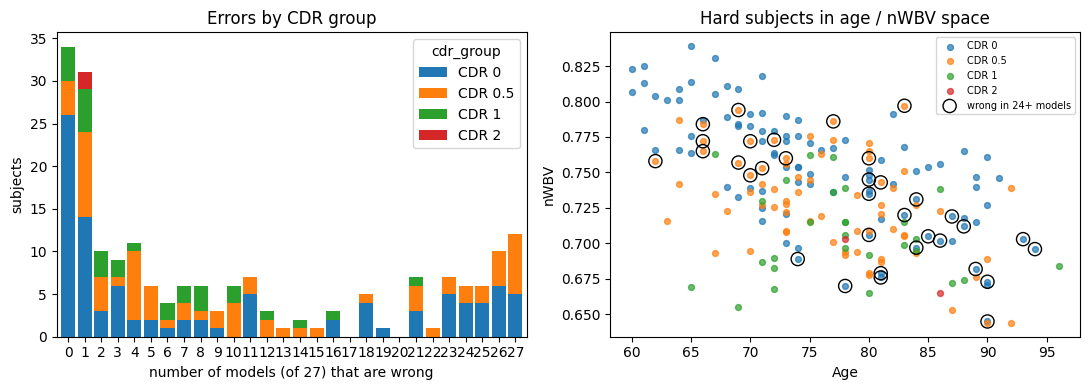

In [21]:
from scipy.stats import fisher_exact

# ---- 1. one row per subject: probability from each model + clinical columns ----
pf = pd.concat([pd.read_csv(p) for p in sorted(ALL.glob(f"{TASK}_*_preds.csv"))])
P = pf.pivot(index="subject", columns="model", values="p1")                       # subjects x models
info = subs.set_index("subject").loc[P.index]
y = info.label_bin.values
assert (pf.drop_duplicates("subject").set_index("subject").y.loc[P.index].values == y).all()

models = list(P.columns)
IMG_NAMES = ["EfficientNet-B0", "ResNet50", "DenseNet201", "MobileNetV2", "ConvNeXt", "ConvNeXt V2", "NFNet", "InceptionNeXt",
             "RepLKNet", "EfficientNetV2", "ViT-B/16", "Swin", "DeiT", "BEiT", "MaxViT", "CAFormer"]
IMG = [m for m in IMG_NAMES if m in models]
GRAPH = [m for m in models if m not in IMG]
wrong = (P.values >= 0.5).astype(int) != y[:, None]                               # True = model is wrong (0.5 cutoff)

df = info.assign(n_wrong=wrong.sum(1),
                 n_wrong_img=wrong[:, [models.index(m) for m in IMG]].sum(1),
                 n_wrong_graph=wrong[:, [models.index(m) for m in GRAPH]].sum(1),
                 mean_p1=P.mean(axis=1).values)
df["consensus_wrong"] = (df.mean_p1 >= 0.5).astype(int) != df.label_bin           # average of all models is wrong
df["cdr_group"] = df.CDR.map(lambda v: f"CDR {v:g}")
K = len(models)
HARD = int(round(K * 8 / 9))            # "wrong in almost all models" (8 of 9 in the original setting)

# ---- 2. how many models miss each subject ----
print(f"{len(df)} subjects, {K} models. Number of models that get each subject wrong (0.5 cutoff):")
print(df.n_wrong.value_counts().sort_index().rename("subjects").to_frame().T.to_string())

# ---- 3. error rate by CDR group (the base-rate-safe view) ----
tab = df.groupby("cdr_group").agg(subjects=("n_wrong", "size"),
                                  share_of_models_wrong=("n_wrong", lambda s: s.mean() / K),
                                  consensus_error=("consensus_wrong", "mean"),
                                  wrong_in_all=("n_wrong", lambda s: int((s == K).sum())),
                                  wrong_in_90pct=("n_wrong", lambda s: int((s >= HARD).sum())))
print("\nBy CDR group:")
print(tab.round(2).to_string())

pos = df[df.label_bin == 1]
a, b = pos[pos.CDR == 0.5].consensus_wrong, pos[pos.CDR >= 1].consensus_wrong
odds, p = fisher_exact([[int(a.sum()), int((~a).sum())], [int(b.sum()), int((~b).sum())]])
print(f"\nAmong demented subjects, the models' average is wrong for {a.mean():.0%} of CDR 0.5 ({len(a)} subjects) "
      f"vs {b.mean():.0%} of CDR 1+ ({len(b)} subjects); Fisher exact p = {p:.3g}")
miss = pos[pos.consensus_wrong]
print(f"CDR 0.5 makes up {(pos.CDR == 0.5).mean():.0%} of demented subjects and "
      f"{(miss.CDR == 0.5).mean() if len(miss) else float('nan'):.0%} of the {len(miss)} demented subjects the average misses "
      f"(if these two shares are close, 'mostly CDR 0.5' is just the base rate)")

# ---- 4. the hardest subjects ----
cols = ["ID", "fold", "CDR", "Age", "sex", "nWBV", "MMSE", "mean_p1", "n_wrong"]
print(f"\nSubjects wrong in at least {HARD} of {K} models ({int((df.n_wrong >= HARD).sum())}), most-missed first:")
print(df[df.n_wrong >= HARD].sort_values(["n_wrong", "mean_p1"], ascending=[False, False])[cols].round(2).head(30).to_string())

# ---- 5. what distinguishes the subjects the average gets wrong ----
g = df.groupby(["label_bin", "consensus_wrong"])
print("\nMeans by true label (0 = CDR 0, 1 = CDR > 0) and whether the model average is wrong:")
print(g[["Age", "nWBV", "MMSE", "eTIV"]].mean().round(2).join(g.size().rename("n")).to_string())

# ---- 6. do the two model families make the same mistakes? ----
R = P.corr(method="spearman")
def mean_r(A, B_): return float(np.mean([R.loc[i, j] for i in A for j in B_ if i != j]))
print(f"\nMean Spearman correlation of subject scores: within image models {mean_r(IMG, IMG):.2f}, "
      f"within graph models {mean_r(GRAPH, GRAPH):.2f}, between families {mean_r(IMG, GRAPH):.2f}")
print("Majority of the family wrong (rows: image models, columns: graph models):")
print(pd.crosstab(df.n_wrong_img > len(IMG) / 2, df.n_wrong_graph > len(GRAPH) / 2, rownames=["image majority wrong"], colnames=["graph majority wrong"]))

# ---- 7. plots and saved table ----
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ct = pd.crosstab(df.n_wrong, df.cdr_group).reindex(range(K + 1), fill_value=0)
ct.plot(kind="bar", stacked=True, ax=ax[0], width=0.85, rot=0)
ax[0].set_xlabel(f"number of models (of {K}) that are wrong"); ax[0].set_ylabel("subjects"); ax[0].set_title("Errors by CDR group")
for grp, d in df.groupby("cdr_group"):
    ax[1].scatter(d.Age, d.nWBV, s=18, alpha=0.7, label=grp)
h = df[df.n_wrong >= HARD]
ax[1].scatter(h.Age, h.nWBV, s=90, facecolors="none", edgecolors="k", label=f"wrong in {HARD}+ models")
ax[1].set_xlabel("Age"); ax[1].set_ylabel("nWBV"); ax[1].legend(fontsize=7); ax[1].set_title("Hard subjects in age / nWBV space")
plt.tight_layout(); plt.savefig(ALL / "error_analysis.png", dpi=150); plt.show()
df.reset_index().to_csv(ALL / "error_analysis_subjects.csv", index=False)